# 🌸 ФИНАЛЬНЫЙ АНАЛИЗ РОЗНИЧНОГО ЦВЕТОЧНОГО МАГАЗИНА · данные из Бизнес.Ру

---

## 📑 Содержание

| Раздел | О чём |
|---|---|
| [0. Инструкция для новичка](#шаг0) | как запустить блокнот за 3 минуты |
| [1. Где взять данные в Бизнес.Ру](#шаг1) | какие отчёты, где нажать, что скачать — по кнопкам |
| [2. Как воруют флористы](#шаг2) | 15 способов хищений и как каждый видно в данных |
| [3. Настройки](#шаг3) | единственная ячейка, которую нужно править |
| [4–5. Загрузка данных](#шаг4) | умное чтение файлов Бизнес.Ру, разбор «Движения товаров» |
| [6. Контроль качества](#шаг6) | сходятся ли остатки, нет ли дыр в выгрузке |
| [7. KPI](#шаг7) | выручка, маржа, средний чек — главными цифрами |
| [8. Динамика](#шаг8) | выручка по дням, тренд |
| [9. Дни недели и часы](#шаг9) | когда магазин зарабатывает |
| [10. Праздники](#шаг10) | 8 марта, 14 февраля и т.д. — пики цветочного бизнеса |
| [11. ABC / XYZ / BCG](#шаг11) | кто кормит магазин, что нестабильно, что растёт |
| [12. Категории](#шаг12) | розы, срезка, горшечные, упаковка |
| [13. Чек и Market Basket](#шаг13) | средний чек и «что покупают вместе» |
| [13.1 RFM клиентов](#шаг13b) | 💎 лучшие, 🚨 уходящие — кого вернуть звонком |
| [14. Цены и маржа](#шаг14) | где теряем деньги |
| [15. Склад: залежи и план закупки](#шаг15) | что зависло и что заказать на N дней |
| [15.1 Сезонность товаров](#шаг15b) | что и в каком месяце покупать заранее |
| [16. Прогноз выручки](#шаг16) | простой и честный прогноз с проверкой точности |
| [17. Детектор потерь и хищений](#шаг17) | невязки, пики списаний, возвраты, сверка с кассой |
| [18. Карточка сотрудника + ML](#шаг18) | риск-балл каждого флориста и Isolation Forest |
| [19. Резюме для владельца](#шаг19) | что сказать bosses'у одним экраном |
| [20. Выгрузка в Excel](#шаг20) | все таблицы одним файлом |
| [21. Куда расти: DS / BI / продуктовая аналитика](#шаг21) | следующие шаги |

<a id='шаг0'></a>
# 0. 🚀 Инструкция для новичка: как запустить за 3 минуты

1. **Установите Python** (один раз): скачайте с [python.org](https://www.python.org/downloads/) и обязательно поставьте галочку *«Add Python to PATH»* при установке.
2. **Установите библиотеки** (один раз). Откройте терминал (Windows: «Командная строка», Mac: «Терминал») и выполните:
   ```bash
   pip install jupyterlab pandas numpy matplotlib openpyxl xlrd scikit-learn
   ```
   *(`xlrd` нужен, чтобы читать старые файлы `.xls`, которые отдаёт Бизнес.Ру; `scikit-learn` — для раздела про машинное обучение, без него блокнот всё равно работает)*
3. **Положите выгрузки Бизнес.Ру в папку `data/`** рядом с этим блокнотом. Имена можно менять как угодно — блокнот найдёт файлы по ключевым словам в названии: «движение», «продаж», «списан», «поступлен», «остатк», «инвентаризац», «контроль», «реализа».
4. **Запустите**: в терминале в папке с блокнотом выполните `jupyter lab`, откройте этот `.ipynb` и нажмите **▶ Run All** (или меню *Run → Run All Cells*). Через минуту весь отчёт будет готов.
5. **Нет под рукой данных?** В ячейке «Настройки» поставьте `USE_DEMO = True` — блокнот создаст учебный цветочный магазин и покажет, как выглядит готовый анализ. Для своих данных верните `False`.
6. **Менять ничего не нужно**, кроме одной ячейки «Настройки» (раздел 3): период анализа, пороги, путь к папке.
7. **Работает в любом магазине** (универсально): если файлы называются по-другому — допишите свои слова в `FILE_KEYWORDS`; если колонки в выгрузке с другими именами — добавьте соответствие в `COLUMN_ALIASES`; а чтобы анализировать одну торговую точку — поставьте `STORE_FILTER = 'Курская'` (или уберите оптовый склад через `EXCLUDE_STORE = 'Оптовый'`).

### Что делать, если что-то пошло не так?

| Симптом | Решение |
|---|---|
| `FileNotFoundError: Нет папки data` | создайте папку `data` рядом с блокнотом и положите туда файлы |
| `Нет файла «Движение товаров»` | скачайте этот отчёт в Бизнес.Ру (раздел 1 ниже) и кладите в `data/` |
| Графики без русских букв | не актуально: блокнот использует шрифт DejaVu Sans, который поддерживает кириллицу |
| `XLRDError` | файл на самом деле не `.xls`, а HTML/xlsx — переоткройте его в Excel и пересохраните |
| Долго считается | данных мало (тысячи строк) — значит, проблема не в скорости, а в шаге выше 🙂 |

<a id='шаг1'></a>
# 1. 📥 Где брать данные в Бизнес.Ру — подробно, по кнопкам

Ваш адрес: **https://w746008.business.ru/supply** → слева вертикальное меню разделов: *Продажи, Закупки (`supply`), Склад, Услуги, Финансы, Отчёты, Настройки*.

> ⚠️ **Честная оговорка.** Названия пунктов меню Бизнес.Ру ниже даны по типовой версии и по вашим прошлым выгрузкам; у разных тарифов и версий они могут чуть отличаться (например «Движение товаров» может лежать в «Отчётах»). Если пункта нет — воспользуйтесь поиском по меню или напишите в поддержку Бизнес.Ру названием отчёта. Блокнот от меню не зависит: ему важны только сами файлы.

Общий принцип выгрузки везде одинаковый:

> **Раздел → нужный отчёт → задать период → «Открыть» → кнопка «Экспорт» (значок ⬇ над таблицей) → формат «Файл Excel» или «CSV» → скачать.**

Ниже — карта всех нужных отчётов. Отмечено, что **обязательно**, а что полезно. Сейчас анализируем **только розницу** — поэтому всегда выбирайте розничный склад (например «Основной склад» / «Курская»), а оптовый склад не берите.

---

### 🥇 №1. «Движение товаров» — ОБЯЗАТЕЛЬНО (главный файл)

Самый ценный отчёт: в нём **каждая продажа видна как отдельный чек** с датой и временем, плюс начальный/конечный остаток по каждому товару.

**Где:** меню **«Склад» → «Движение товаров»** (в некоторых версиях: **«Отчёты» → «Складские отчёты» → «Движение товара»**).

**Как выгрузить по шагам:**
1. Выберите **склад** — только розничный.
2. Укажите **период** (например 01.10.2026 – 31.10.2026). Совет: выгружайте на 3–5 дней раньше начала месяца, чтобы «начальный остаток» был корректным.
3. Нажмите **«Открыть»**, дождитесь построения таблицы.
4. Над таблицей — **«Настроить» / шестерёнка** → убедитесь, что включены колонки: *Начальный остаток, Приход, Расход, Конечный остаток* (кол-во, себестоимость, сумма) и детализация **«по документам»** (чтобы под каждым товаром шли строки чеков/списаний).
5. **«Экспорт» → «Файл Excel (.xls)»** (именно этот файл у вас приходит как `.xls` — блокнот умеет).

**Что внутри:** товар → склад → документы (чеки, поступления, списания, перемещения) с количеством и себестоимостью. Из него блокнот делает таблицу чеков, остатки и дневную кривую списаний.

📌 Если в выгрузке только чеки — это нормально (в отчёте стоял фильтр по типу документа). Списания и поступления блокнот возьмёт из отдельных файлов ниже.

---

### 🥈 №2. «Продажи» (итоги по товарам) — ОБЯЗАТЕЛЬНО

Нужен, чтобы узнать **цены продажи**: в «Движении товаров» есть только себестоимость! Без этого файла выручка и маржа будут оценочными.

**Где:** меню **«Отчёты» → «Продажи»** (или **«Продажи» → «Отчёт по продажам»**, вкладка «Товары»).

**Как:** период → «Открыть» → «Экспорт» → Excel/CSV. Нужны колонки: *Товар/Услуга, Кол-во, Себестоимость, Выручка, Торговая наценка*.

---

### 🥉 №3. «Списания» — ОЧЕНЬ ЖЕЛАТЕЛЬНО (для поиска воровства)

**Где:** меню **«Склад» → «Списания»** (либо в «Движении товаров» фильтр по типу «Списание»).

Список документов «Списание №… от дата» с суммами и **причинами**. Это основа контроля: ложное списание «на порчу» — самый частый способ скрыть кражу.

⚠️ Два важных нюанса этой выгрузки:
1. В списке документов сумма обычно считается **по ценам продажи** (розничной стоимости), а не по себестоимости. Блокнот это учитывает (настройка `WO_AMOUNT_IS_RETAIL`), но для точности лучше выгружать **«Склад → Ведомость по товарам»** с типом документа «Списание» — там суммы по позициям и по себестоимости.
2. Если вместо списаний скачается «Поступления» (суммы закупок тоже большие!), блокнот предупредит: медианная сумма ≥ 100 тыс. ₽ — явный признак перепутанных файлов.

---

### №4. «Поступления» — желательно (закупки, поставщики)

**Где:** меню **«Закупки» → «Поступления»** — это как раз ваша страница `https://w746008.business.ru/supply`. Там видно: от кого, когда и по какой цене пришло. Нужно для анализа закупочных цен и наценок по партиям.

---

### №5. «Остатки товаров» — желательно (срез склада на дату)

**Где:** **«Склад» → «Остатки товаров»** (или «Отчёты» → «Остатки»). Нужен, чтобы сверять фактический остаток с расчётным.

---

### №6. «Инвентаризации» — ЗОЛОТАЯ ЖИЛА для поиска реальных потерь

**Где:** **«Склад» → «Инвентаризации»**. В самой карточке инвентаризации Бизнес.Ру показывает колонки *«По учётным данным»* и *«Фактически»* — разница между ними и есть **недостача/излишек**. Выгружайте каждую инвентаризацию (особенно слепые!) — минус по ходовым позициям без документов = прямое следствие хищения.

---

### №7. Ваши кассовые таблицы (`Курская_Контроль_*.xlsx`)

Это ваш внутренний контроль кассы: нал/безнал по сотрудникам, ЗП, разница «расчёт/факт». Блокнот читает лист «Касса», если файл лежит в `data/`, и использует его в разделе 17 (сверка «Движение ↔ Касса» — ловля непробитых продаж).

---

### ✅ Минимальный набор на каждый месяц

| Файл | Обязателен? | Даёт |
|---|---|---|
| Движение товаров | ✅ да | чеки, время, остатки, движения |
| Продажи | ✅ да | цены продажи → выручка и маржа |
| Списания | ➕ очень надо | контроль хищений через «порчу» |
| Инвентаризации | ➕ очень надо | реальные недостачи |
| Поступления | ➕ | закупочные цены, поставщики |
| Остатки | ➕ | сверка склада |
| Касса (ваш XLSX) | ➕ | сверка денег и чеков |
| Реализации / P&L | ⚪ опционально | опт, прибыль целиком |

> 💡 **Лайфхак:** в Бизнес.Ру есть **«Настройки → Шаблоны отчётов»** — сохраните шаблон «Движение товаров» с нужными колонками и периодом «текущий месяц», тогда ежемесячная выгрузка = 2 клика.
> 💡 **Про «Владельца» в документах:** в выгрузках «Списания/Поступления» есть колонка *Владелец* — это тот, кто создал документ в системе. Это бесплатная «привязка операции к сотруднику», используйте её (раздел 18). Но помните: владелец ≠ кассир, который пробил чек; кассира видно в журнале смен / на фискальном накопителе (ОФД).

<a id='шаг2'></a>
# 2. 🕵️ Как воруют флористы в цветочном магазине — способы и признаки

Цветочный магазин — зона высокого риска: **скоропортящийся товар (можно всегда объяснить «засохло»), ручная сборка букетов, много «бесхозных» движений, наличка**. Ниже — реальные схемы по этапам и **цифры, по которым каждая схема видна в данных**. Разделы 17–18 блокнота автоматически ищут эти признаки.

### A. Хищения на кассе (самые частые)

| # | Способ | Как выглядит | Что «кричит» в данных |
|---|---|---|---|
| 1 | **«Минусовка» / отмена чека** | Пробил товар → сделал «возврат без клиента» → забрал деньги из кассы | Волна «возвратов» в конце смены (после 18:00); у одного сотрудника возвратов в разы больше, чем у коллег; возвращённый товар потом ни разу не продаётся |
| 2 | **Непробитая продажа («мимо кассы»)** | Продал букет за наличные, чек не пробил | Товар уходит со склада (расход по Движению есть), а чека нет; **расхождение «Движение ↔ Касса»**; на инвентаризации — минус |
| 3 | **Занижение суммы / «продажа по себе»** | Пробил дешевле прайса или «скидку другу» | Средняя цена конкретного товара у одной смены системно ниже, чем у коллег; всплески скидок >15% без карты клиента |
| 4 | **Подмена способа оплаты** | Наличку провели картой «на свою», потом «вернули» | Недостача в кассе компенсируется серией банковских возвратов на одну карту |
| 5 | **Работа «в парах»** | Один отвлекает покупателя/камеру, второй не пробивает | Провалы среднего чека в конкретные часы при конкретной паре сотрудников |

### B. Хищения через документы

| # | Способ | Как выглядит | Признак в данных |
|---|---|---|---|
| 6 | **Ложное списание «на порчу»** | Украли цветы → оформили как «засохло» | Резкие пики списаний в конце смены/месяца; списания у одного сотрудника ×N выше средних; списывается то, что отлично продаётся (ходовые розы, а не неликвид) |
| 7 | **Списание задним числом** | Документ «вчерашний», создан сегодня вечером | Дата документа ≠ время создания; всплески сумм списаний «пачкой» одним днём; в Бизнес.Ру смотрите «Журнал изменений» (Настройки → история документов) |
| 8 | **Фиктивные возвраты поставщику** | «Вернули брак» — забрали домой | Возвраты поставщику без поступлений этого товара; регулярные «браки» у одного поставщика-«друга» |
| 9 | **Пересортица** | В отчётности дорогая роза превратилась в дешёвую | Плюс одного SKU ≈ равен минусу другого SKU в один день/смену |
| 10 | **Завышение закупочной цены (сговор)** | В документе цена выше реальной, разницу делят с менеджером | Цена закупки одного товара скачет между партиями без причины; сверка «Поступления vs прайс поставщика» |

### C. Хищения самим товаром

| # | Способ | Признак |
|---|---|---|
| 11 | **Прямая кража со склада/холодильника** | Минус на инвентаризации без документов; «дыра» между (нач. остаток + приход − расход) и конечным остатком |
| 12 | **«Лишний» материал при сборке** | Расход зелени/упаковки на букет систематически выше нормы (заведите нормы: например, эвкалипт ≤ 3 ветки на средний букет) |
| 13 | **Букет «для себя»** | Комплектующие куплены и списаны, а продажи готового букета нет |
| 14 | **Использование клиентских цветов** | Принесли на оформление/свадьбу — часть «не вернулась»; учитывайте услуги отдельным документом |
| 15 | **Кража денег из кассы напрямую** | Недостача в кассовых таблицах (разница «расчёт/факт» < 0) |

### ⚖️ Почему «красный флаг» ≠ вор (невинные объяснения)

У каждого сигнала есть честные версии: высокий % списаний — человек принимает поставки и отвечает за холодильник; возвраты — он просто работает на кассе в «проблемные» часы и принимает претензии; скидки — ведёт постоянных клиентов по картам; низкая выручка за смену — ему достались тихие будни. **Поэтому смотрите совокупность флагов (риск-балл) и сравнивайте людей между собой, а не с абстрактной нормой.**

### 🧮 Как эти схемыперевести в цифры — см. раздел 17б «ГДЕ УТЕЧКА» (блокнот считает три слоя потерь автоматически)

### 🛡 Профилактика (что реально работает)

1. **Слепые инвентаризации 1–2 раза в неделю** по топ-20 ABC-товаров (розы, ходовая срезка) — без предупреждения, пересчёт «в лоб».
2. **Видео над зоной сборки и холодильником** + правило: «букет без чека не собирается».
3. **Все возвраты/отмены — только со старшим смены**, с указанием причины; журнал отмен.
4. **Списания «на порчу» — с фото** каждой партии и подписью двух человек.
5. **Ежедневная авто-сверка**: сумма чеков дня ≈ выручка кассы; расход по Движению ≈ продажи + списания. Любая разница > 1% — вопрос к смене.
6. **Матричная ротация** сотрудников по сменам и выходным — чтобы никто не «владел» участком.
7. **Мотивация через % от маржи, а не от выручки** — снижает соблазн занижать цены.
8. **Сравнение показателей между сотрудниками** (раздел 18) — главный математический инструмент: воришка виден как статистический выброс.

<a id='шаг3'></a>
# 3. ⚙️ Настройки — менять только здесь

Единственная ячейка, которую нужно править. Всё остальное работает «из коробки».

In [50]:
# ╔══════════════════════════════════════════════════════════════╗
# ║            НАСТРОЙКИ — МЕНЯТЬ ТОЛЬКО В ЭТОЙ ЯЧЕЙКЕ          ║
# ╚══════════════════════════════════════════════════════════════╝
DATA_DIR      = 'data'    # папка с выгрузками из Бизнес.Ру
USE_DEMO      = False     # True = нет своих данных? Создать учебный магазин и прогнать анализ на нём
DATE_FROM     = None      # None = со старта данных, или '2026-10-01'
DATE_TO       = None      # None = до конца данных,   или '2026-10-31'

TOP_N         = 15        # сколько товаров показывать в рейтингах
SLOW_DAYS     = 21        # нет продаж столько дней → товар «залёжался»
COVER_DAYS    = 4         # на сколько дней вперёд держать запас цветов
COVER_LOOKBACK = 28       # по продажам за сколько дней считать скорость
GLOBAL_MARKUP = 2.0       # запасная наценка ×2, если цены продажи нигде нет
MARGIN_TARGET = 40        # целевая маржинальность, % (для красной подсветки)

# Корзинный анализ
MIN_SUPPORT    = 0.003    # минимальная доля чеков для пары товаров
MIN_PAIR_COUNT = 5        # пара должна встретиться хотя бы в N чеках
EXCLUDE_FROM_BASKET = ['Услуги флориста']  # сборка есть почти в каждом чеке — портит связки

# Прогноз
FORECAST_DAYS = 14

# Клиенты (раздел 13.1) и сезонность (раздел 15.1)
RFM_MIN_CLIENTS = 20      # меньше N известных клиентов — RFM нерепрезентативен, раздел пропустится
SEASON_MONTHS   = 6       # для карты «товар × месяц» нужно минимум столько месяцев истории

# Детектор потерь (раздел 17)
WRITEOFF_SPIKE_KOEF = 2.0 # списание в N раз больше медианы дня = подозрение
RETURN_RATE_ALERT   = 5.0 # доля возвратов в чеках > X% = подозрение
PRICE_DISCOUNT_PCT  = 15  # продажа дешевле медианной цены на X% = «пробил себе»
CASH_DIFF_PCT       = 5   # расхождение Движение↔Касса больше X% = сигнал

# Риск-скоринг сотрудников (раздел 18)
FLAG_RATIO   = 2.0        # показатель хуже медианы коллег в N раз = флаг
WORK_START   = 9          # начало рабочего дня (операции вне = флаг)
WORK_END     = 21         # конец рабочего дня

# ─────────── ВАЖНО ПРО ФАЙЛ «СПИСАНИЯ» ───────────
# Бизнес.Ру в списке документов «Списания» часто показывает сумму ПО РОЗНИЧНОЙ ЦЕНЕ,
# а не по себестоимости. Если суммы списаний кажутся вам слишком большими (как будто
# продали, а не испортили) — оставьте True: блокнот пересчитает их в себестоимость
# через среднюю себестоимость проданного цветка и честно предупредит, что это оценка.
WO_AMOUNT_IS_RETAIL = True

EXPORT_XLSX   = True      # сохранить все таблицы в Excel (раздел 20)
OUTPUT_DIR    = 'output'

# ─────────── УНИВЕРСАЛЬНЫЕ НАСТРОЙКИ (для любого магазина) ───────────
# Ключевые слова для поиска файлов в папке data/ (имена могут быть любые).
FILE_KEYWORDS = {
    'движение': ('движение', 'movement'),        # Склад → Движение товаров (ОБЯЗАТЕЛЬНО)
    'продаж':   ('продаж', 'sales'),            # Продажи → Отчёт по продажам
    'поступлен':('поступлен', 'purchase'),      # Закупки → Поступления
    'списан':   ('списан', 'writeoff'),         # Склад → Списания
    'остатк':   ('остатк', 'stock'),            # Склад → Остатки товаров
    'инвентаризац': ('инвентаризац',),          # Склад → Инвентаризации
    'контроль': ('контроль', 'касса'),           # ваш файл сверки кассы (.xlsx)
    'реализа':  ('реализа',),                   # Заказы покупателей (опт) — не для розницы
}
# Если в вашей выгрузке колонки называются иначе — допишите соответствие сюда.
# Формат: {'имя_которое_ждёт_блокнот': 'имя_в_вашем_файле'}
COLUMN_ALIASES = {}          # пример: {'Склад': 'Магазин', 'Владелец': 'Ответственный'}
STORE_FILTER  = None         # None = все склады; или строка-подстрока, напр. 'Курская' (только эта точка)
EXCLUDE_STORE = None         # или исключить склад подстрокой, напр. 'Оптовый'

print('✅ Настройки загружены')

✅ Настройки загружены


<a id='шаг4'></a>
# 4. 📦 Библиотеки и помощники

Ничего менять не нужно — просто ячейка с «инструментами»: чтение любых форматов Бизнес.Ру, очистка чисел вида `1 234,50 шт.`, поиск файлов по имени, автоматические категории товаров.

In [51]:
import os, re, warnings
from pathlib import Path
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
try:
    display
except NameError:
    display = print

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': '#F8F9FA', 'axes.facecolor': '#F8F9FA',
    'axes.grid': True, 'grid.alpha': .4, 'grid.linestyle': '--',
})

PALETTE = ['#2563EB','#10B981','#F59E0B','#EF4444','#8B5CF6','#EC4899',
           '#06B6D4','#84CC16','#F97316','#6366F1','#14B8A6','#FBBF24']
ABC_COLORS = {'A':'#10B981','B':'#F59E0B','C':'#EF4444'}
DAYS_RU = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']

def rub(v):
    return '—' if pd.isna(v) else f'{v:,.0f} ₽'.replace(',', ' ')
def num_fmt(v):
    return '—' if pd.isna(v) else f'{v:,.0f}'.replace(',', ' ')
def pct(v):
    return '—' if pd.isna(v) else f'{v:.1f}%'
def fmt_rub_axis(x, pos=None):
    if abs(x) >= 1_000_000: return f'{x/1e6:.1f}М'
    if abs(x) >= 1_000:     return f'{x/1e3:.0f}К'
    return f'{x:.0f}'
def norm_name(s):
    return re.sub(r'[\s_]+',' ',str(s).lower().replace('ё','е')).strip()
def _num_one(x):
    '''Превращает ОДНУ ячейку в число. Понимает русский и американский формат:
    «1 234,50», «1234.5», «1.234,56», «1,234.56», «10733<перенос строки>84» (копейки на 2-й строке),
    «12 шт.», «-5». Пустое/мусор -> NaN.
    ГЛАВНОЕ ИСПРАВЛЕНИЕ: раньше запятая удалялась как «разделитель тысяч», и «250,50» превращалось
    в 25050 (в 100 раз больше!). Теперь последний разделитель — это десятичная часть.'''
    if x is None: return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)
    t = str(x).replace('\u00a0', ' ').strip()
    if t == '' or t.lower() in ('nan', 'none', '-', '—'): return np.nan
    m = re.fullmatch(r'(-?[\d\s.,]*\d)\s*[\r\n]+\s*(\d{1,2})', t)       # «лесенка»: рубли \n копейки
    if m:
        t = re.sub(r'[\s.,]', '', m.group(1)) + '.' + m.group(2)
    t = re.sub(r'[^0-9.,\-]', '', t)
    if not re.search(r'\d', t): return np.nan
    neg = t.startswith('-')
    t = t.replace('-', '')
    if ',' in t and '.' in t:                       # оба знака: десятичный — тот, что правее
        dec = ',' if t.rfind(',') > t.rfind('.') else '.'
        thou = '.' if dec == ',' else ','
        t = t.replace(thou, '').replace(dec, '.')
    elif ',' in t:                                  # только запятые: по-русски это десятичная
        parts = t.split(',')
        t = ''.join(parts[:-1]) + '.' + parts[-1]
    elif t.count('.') > 1:                          # «1.234.567» — точки это тысячи
        parts = t.split('.')
        t = ''.join(parts) if all(len(p) == 3 for p in parts[1:]) else ''.join(parts[:-1]) + '.' + parts[-1]
    try:
        v = float(t)
    except ValueError:
        return np.nan
    return -v if neg else v

def to_num(s):
    '''Серия (колонка) -> числа. См. _num_one.'''
    return pd.Series(s).map(_num_one).astype(float) if not isinstance(s, pd.Series) else s.map(_num_one).astype(float)
def scalar_num(v):
    if v is None or (isinstance(v,float) and np.isnan(v)): return 0.0
    try: return float(str(v).replace('\xa0','').replace(' ','').replace(',','.'))
    except ValueError: return 0.0

def find_file(*keywords, ext=('.csv','.xls','.xlsx')):
    '''Ищет в DATA_DIR файл по ключевым словам. Ключи можно задавать словами из
    настроек (например find_file('движение')) — тогда список берётся из FILE_KEYWORDS,
    и новичок может поменять слова под свои имена файлов, не трогая код ниже.'''
    if not os.path.isdir(DATA_DIR):
        raise FileNotFoundError(f'Нет папки «{DATA_DIR}». Создайте её рядом с блокнотом и положите выгрузки.')
    kws = []
    for kw in keywords:
        kws.extend(FILE_KEYWORDS.get(norm_name(kw), (kw,)))
    for f in sorted(os.listdir(DATA_DIR)):
        fl = norm_name(f)
        if f.lower().endswith(ext) and not f.startswith('~') and not f.startswith('.'):
            for kw in kws:
                if norm_name(kw) in fl:
                    return os.path.join(DATA_DIR, f)
    return None

def apply_aliases(df):
    '''Переименовывает колонки по словаре COLUMN_ALIASES (универсальность под чужие выгрузки).'''
    if not COLUMN_ALIASES: return df
    ren = {}
    norm_map = {norm_name(c): c for c in df.columns}
    for want, have in COLUMN_ALIASES.items():
        if norm_name(have) in norm_map and norm_name(want) not in norm_map:
            ren[norm_map[norm_name(have)]] = want
    return df.rename(columns=ren)

def read_csv_smart(path, **kw):
    '''CSV из Бизнес.Ру: подбираем разделитель (, или ;) и кодировку (utf-8/cp1251).
    ВАЖНО: Бизнес.Ру кладёт в ячейки многострочный текст внутри кавычек, а в числах —
    «лесенку» из пробелов (например «10733\\n   84»). Обычный read_csv на этом ломается,
    поэтому читаем через модуль csv (он понимает кавычки), склеиваем строки документа
    и чистим числа от внутренних переводов строк.'''
    import csv as _csv
    from io import StringIO
    last = None
    for enc in ('utf-8-sig', 'cp1251', 'utf-8'):
        try:
            with open(path, encoding=enc, newline='') as fh:
                head = fh.readline()
            if not head.strip():
                raise UnicodeDecodeError(enc, b'', 0, 1, 'пустой файл')
            n_cols = len(next(_csv.reader([head], delimiter=';' if head.count(';') >= head.count(',') else ',')))
            delim = ';' if head.count(';') >= head.count(',') else ','
            rows = []
            with open(path, encoding=enc, newline='') as fh:
                for rec in _csv.reader(fh, delimiter=delim):
                    if not rec:
                        continue                          # пустые строки пропускаем
                    if rows and len(rec) < n_cols:        # «хвост» многострочной ячейки
                        merged = [a + ' ' + b for a, b in zip(rows[-1], rec)]
                        merged += list(rec[len(rows[-1]):])
                        rows[-1] = merged
                    elif rows and len(rec) > n_cols:      # лишние колонки склеиваем в последнюю
                        rows.append(rec[:n_cols-1] + [' '.join(rec[n_cols-1:])])
                    else:
                        rows.append(list(rec))
            buf = StringIO()
            _csv.writer(buf, delimiter=delim, lineterminator='\n').writerows(rows)
            buf.seek(0)
            df = pd.read_csv(buf, sep=delim, dtype=str, **kw)
            # «Итого» у Бизнес.Ру хранится лесенкой: «10733   84» -> «1073384», иначе to_num не сработает
            icol = next((c for c in df.columns if norm_name(c) in ('итого','сумма')), None)
            if icol is not None:
                df[icol] = df[icol].astype(str).str.replace(r'[ \u00a0]+', '', regex=True)
            for c in df.columns:                            # служебные nan -> пусто
                df[c] = df[c].where(df[c].notna(), np.nan)
            return apply_aliases(df)
        except (UnicodeDecodeError, _csv.Error) as e:
            last = e
    raise RuntimeError(f'Не удалось прочитать {path}: {last}')

def read_table_any(path, header=None):
    '''Универсальное чтение: .xls (xlrd), .xlsx (openpyxl), .csv — одним вызовом.
    Бизнес.Ру иногда отдаёт под видом .xls файл другого формата (xlsx или HTML-таблицу) —
    пробуем все варианты по очереди.'''
    p = Path(path); suf = p.suffix.lower()
    if suf == '.xls':
        try:
            return apply_aliases(pd.read_excel(p, header=header, dtype=str, engine='xlrd'))
        except ImportError:
            # xlrd — библиотека для старых .xls. Пробуем поставить её сами (нужен интернет).
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd'], check=False)
            try:
                return apply_aliases(pd.read_excel(p, header=header, dtype=str, engine='xlrd'))
            except ImportError:
                raise ImportError('Для чтения .xls нужна библиотека xlrd. Выполните в терминале: pip install xlrd '
                                  '(или откройте файл в Excel и сохраните как .xlsx)')
        except Exception as e_xls:
            try:
                return apply_aliases(pd.read_excel(p, header=header, dtype=str, engine='openpyxl'))
            except Exception:
                try:
                    return apply_aliases(pd.read_html(str(p), header=header)[0].astype(str))
                except Exception:
                    raise RuntimeError(f'Не удалось прочитать {p.name}: {e_xls}. Откройте файл в Excel и сохраните как .xlsx')
    if suf == '.xlsx':
        return apply_aliases(pd.read_excel(p, header=header, dtype=str, engine='openpyxl'))
    return read_csv_smart(p, header=header)

def read_table_smart(path, max_head_rows=15):
    '''Читает «обычную» таблицу Бизнес.Ру (Списания, Поступления, Инвентаризации...):
    сам находит строку-шапку (она не всегда первая — сверху бывают заголовок отчёта и период),
    склеивает двухэтажные шапки («Сумма» над «Факт» → «Сумма, Факт») и убирает пустые строки/колонки.
    Возвращает DataFrame с нормальными именами колонок.'''
    raw = read_table_any(path)
    raw = raw.dropna(how='all').dropna(axis=1, how='all').reset_index(drop=True)
    raw.columns = list(range(raw.shape[1]))
    def _text_cells(row):
        return [str(v).strip() for v in row if pd.notna(v) and str(v).strip() not in ('', 'nan')]
    def _is_texty(row):
        cells = _text_cells(row)
        return len(cells) >= 2 and sum(pd.notna(_num_one(c)) for c in cells) <= 0.3 * len(cells)
    hdr = None
    for i in range(min(max_head_rows, len(raw))):
        if _is_texty(raw.iloc[i]) and len(_text_cells(raw.iloc[i])) >= max(2, 0.5 * raw.shape[1]):
            hdr = i; break
    if hdr is None:
        hdr = 0
    names = [str(v).strip() if pd.notna(v) else '' for v in raw.iloc[hdr]]
    data_start = hdr + 1
    # двухэтажная шапка: следующая строка тоже «текстовая» → склеиваем
    if data_start < len(raw) and _is_texty(raw.iloc[data_start]) and len(_text_cells(raw.iloc[data_start])) >= 2:
        parent, last = [], ''
        for n in names:
            last = n or last; parent.append(last)
        sub = [str(v).strip() if pd.notna(v) else '' for v in raw.iloc[data_start]]
        names = [f'{p}, {s}' if (s and p and s != p) else (s or p) for p, s in zip(parent, sub)]
        data_start += 1
    seen = {}
    final = []
    for j, n in enumerate(names):
        n = n or f'колонка_{j}'
        seen[n] = seen.get(n, 0) + 1
        final.append(n if seen[n] == 1 else f'{n}_{seen[n]}')
    out = raw.iloc[data_start:].copy()
    out.columns = final
    out = out.dropna(how='all').reset_index(drop=True)
    return apply_aliases(out)

def pick_col(df, *parts, exclude=()):
    '''Находит колонку, в имени которой есть ВСЕ подстроки parts (и ни одной из exclude).'''
    for c in df.columns:
        s = norm_name(c)
        if all(p in s for p in parts) and not any(e in s for e in exclude):
            return c
    return None

UNIT_RE = r',\s*(?:шт|кг|л|м|г|уп|компл|пара|рул|см)\.?\s*$'
def clean_item(s):
    '''Убирает «, шт.» в конце названия, чтобы один и тот же товар в разных отчётах склеивался.'''
    return re.sub(UNIT_RE, '', str(s).strip(), flags=re.IGNORECASE).strip()

def unit_cost_by(df, by):
    '''Средняя себестоимость 1 шт. по группам (быстро, без groupby.apply).'''
    g = df.groupby(by)[['Себестоимость', 'Кол-во']].sum()
    return (g['Себестоимость'] / g['Кол-во'].where(g['Кол-во'] > 0)).rename('uc')

# ---------- Автоматические категории по названию товара ----------
CATEGORY_RULES = [
    ('Услуги флориста',        r'флор\s*услуг|услуга'),
    ('Упаковка и аксессуары',  r'короб|конверт|открытк|пакет|пакт|сумк|кашпо|оазис|декоратив|кризал|грунт|подкормк|лент|ваза|топпер|сетка|плёнк|крафт'),
    ('Горшечные растения',     r'\d+\s*/\s*\d+|фаленопсис|антуриум|шефлер|спатифилиум|сансивиер|цимбидиум|шлюмбергер|эхиверия|инжир|азалия|ало[еэ]|агава|адениум|аглаонема|агапантус|агератум|акалия|алиум'),
    ('Хризантемы',             r'хризантем'),
    ('Розы',                   r'(^|\s)роз[аы]($|\s|[,/])|кустов\w*\s+роз|роз\w*\s+кустов'),
    ('Зелень и наполнители',   r'эвкалипт|папортник|папоротник|аспидистр|рускус|писташ|лист дуба|гипсофил|лимониум|грин трик|скимия|краспедия|танацетум|брасика|молочай|салал'),
]
def categorize(name):
    n = str(name).lower()
    for cat, pat in CATEGORY_RULES:
        if re.search(pat, n):
            return cat
    return 'Прочая срезка'

def barh_labels(ax, labels, values, colors, fmt=rub, pad=.01):
    labels, values = list(labels), list(values)
    ax.barh(labels, values, color=colors)
    top = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + top*pad, i, fmt(v), va='center', fontsize=8.5)
    ax.set_xlim(0, top*1.28 if top > 0 else 1)

print('✅ Библиотеки и функции готовы')

✅ Библиотеки и функции готовы


## 4.0а 🧪 Демо-режим (необязательно)

Если в настройках `USE_DEMO = True`, блокнот сам создаст папку `data_demo/` с придуманными выгрузками (цветы, чеки, возвраты, списания, поставки) и будет работать с ней. Так можно понять, **как выглядит результат**, ещё до выгрузки реальных файлов. Ваши настоящие данные в `data/` при этом не трогаются.

In [52]:
def make_demo_data(folder='data_demo', seed=1):
    """Создаёт учебные файлы «Движение товаров.xlsx» и «Продажи.xlsx» с выдуманным магазином."""
    os.makedirs(folder, exist_ok=True)
    rng = np.random.default_rng(seed)
    names = ['Роза Эквадор 60 см', 'Роза Кения 50 см', 'Роза кустовая Бомбастик', 'Хризантема кустовая белая',
             'Гвоздика красная', 'Тюльпан красный', 'Тюльпан жёлтый', 'Лилия белая', 'Гербера микс', 'Альстромерия',
             'Эвкалипт', 'Гипсофила', 'Рускус', 'Орхидея фаленопсис 12/60', 'Антуриум 12/40', 'Пакет крафт',
             'Лента атласная', 'Открытка', 'Флор услуги сборка букета', 'Ваза стеклянная', 'Подсолнух', 'Пион',
             'Ирис', 'Фрезия', 'Статица', 'Лизиантус', 'Матиола', 'Ранункулюс', 'Гортензия', 'Сирень']
    prices = {}
    for n in names:
        c = int(rng.integers(30, 300)); prices[n] = (c, c * rng.uniform(1.8, 2.6))
    days = pd.date_range('2026-08-01', '2026-10-12')
    docs, chk = [], 0
    for d in days:
        for _ in range(int(rng.integers(8, 25))):
            chk += 1; hr = int(rng.integers(9, 21)); mi = int(rng.integers(0, 60))
            ds = f'Чек №{chk} от {d:%d.%m.%Y} {hr}:{mi:02d}'
            for it in rng.choice(names, size=int(rng.integers(1, 5)), replace=False):
                q = int(rng.integers(1, 5)); docs.append((it, ds, 0, 0, q, q * prices[it][0]))
            if rng.random() < 0.03:
                it = names[int(rng.integers(0, len(names)))]
                docs.append((it, f'Возврат покупателя №{chk}в от {d:%d.%m.%Y} {hr}:{mi:02d}', 1, prices[it][0], 0, 0))
        if rng.random() < 0.3:
            it = names[int(rng.integers(0, len(names)))]; q = int(rng.integers(3, 40))
            docs.append((it, f'Списание №{d.dayofyear} от {d:%d.%m.%Y} 20:10', 0, 0, q, q * prices[it][0]))
        if d.dayofweek in (0, 3):
            for it in names:
                q = int(rng.integers(40, 120)); docs.append((it, f'Поступление №{d.dayofyear}{it[:2]} от {d:%d.%m.%Y} 08:00', q, q * prices[it][0], 0, 0))
    dd = pd.DataFrame(docs, columns=['it', 'ds', 'iq', 'ir', 'oq', 'oc'])
    rows = [['Движение товаров'] + [''] * 15, ['Период'] + [''] * 15,
            ['Наименование', 'Склад', 'Документ', '', 'Начальный остаток'] + [''] * 11,
            [''] * 16]
    for it in names:
        g = dd[dd.it == it]; end = 20 + g.iq.sum() - g.oq.sum()
        rows.append([it + ', шт.', '', '', '', 20, '', '', g.iq.sum(), '', round(g.ir.sum(), 2), g.oq.sum(), '',
                     round(g.oc.sum(), 2), end, '', round(end * prices[it][0], 2)])
        rows.append(['', 'Основной склад'] + [''] * 14)
        for _, r in g.iterrows():
            rows.append(['', '', r.ds, '', '', '', '', r.iq, '', round(r.ir, 2), r.oq, '', round(r.oc, 2), '', '', ''])
    pd.DataFrame(rows).to_excel(os.path.join(folder, 'Движение товаров.xlsx'), header=False, index=False)
    sr = [['Отчёт по продажам', '', '', ''], ['Товар/услуга', 'Кол-во', 'Выручка', 'Себестоимость, сумма']]
    for it in names:
        g = dd[dd.it == it]; sr.append([it + ', шт.', g.oq.sum(), round(g.oq.sum() * prices[it][1], 2), round(g.oc.sum(), 2)])
    pd.DataFrame(sr).to_excel(os.path.join(folder, 'Продажи.xlsx'), header=False, index=False)
    return folder

if USE_DEMO:
    DATA_DIR = make_demo_data()
    print(f'🧪 ДЕМО-РЕЖИМ: анализируем выдуманный магазин из папки «{DATA_DIR}». Своих данных в отчёте нет!')
    print('   Чтобы анализировать реальные выгрузки: USE_DEMO = False в настройках и перезапуск.')


## 4.0 🔎 Самопроверка: какие файлы блокнот нашёл

Если напротив нужного файла стоит ❌ — проверьте, что файл лежит в папке `data/` и в его названии есть ключевое слово (например «Движение товаров.xls»).


In [53]:
print(f'📂 Папка с данными: {os.path.abspath(DATA_DIR)}')
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f'Нет папки «{DATA_DIR}». Создайте её рядом с блокнотом и положите туда выгрузки из Бизнес.Ру.')
print('Все файлы в папке:', [f for f in os.listdir(DATA_DIR) if not f.startswith(('.', '~'))] or 'пусто!')
_roles = [('движение', 'Движение товаров  (ОБЯЗАТЕЛЬНО)'), ('продаж', 'Продажи             (обязательно для цен)'),
          ('списан', 'Списания'), ('поступлен', 'Поступления'), ('остатк', 'Остатки товаров'),
          ('инвентаризац', 'Инвентаризации'), ('контроль', 'Касса (ваш XLSX)')]
for _k, _title in _roles:
    _p = find_file(_k, ext=('.csv', '.xls', '.xlsx'))
    print(('✅' if _p else '❌'), _title.ljust(42), os.path.basename(_p) if _p else 'не найден')
if find_file('движение') is None:
    print('\n⛔ Без файла «Движение товаров» дальше работать нельзя. Скачайте его (раздел 1) и положите в data/.')


📂 Папка с данными: d:\Down\21school\muzflowers_analysis\data
Все файлы в папке: ['Движение товаров.xls', 'Инвентаризации.csv', 'Курская_Контроль_Октябрь.xlsx', 'Оприходования товаров.csv', 'Остатки товаров.csv', 'Поступления.csv', 'Продажи.csv', 'Списания товаров.csv']
✅ Движение товаров  (ОБЯЗАТЕЛЬНО)            Движение товаров.xls
✅ Продажи             (обязательно для цен)  Продажи.csv
✅ Списания                                   Списания товаров.csv
✅ Поступления                                Поступления.csv
✅ Остатки товаров                            Остатки товаров.csv
✅ Инвентаризации                             Инвентаризации.csv
✅ Касса (ваш XLSX)                           Курская_Контроль_Октябрь.xlsx


## 4.1 Загрузка файла «Продажи» → цены продажи

Файл «Продажи» нужен, чтобы к каждой позиции чека прицепить **цену продажи** (в «Движении товаров» её нет). Разбираем шапку «как есть» — Бизнес.Ру часто выводит её в необычных местах листа.

In [54]:
def load_sales_prices(path):
    raw = read_table_any(path)
    if isinstance(raw.columns[0], str):     # CSV прочитался с заголовком — вернём его как строку данных
        hdr = pd.DataFrame([raw.columns]); raw = pd.concat([hdr, raw], ignore_index=True)
    raw = raw.dropna(how='all')
    # находим строку-шапку: в ней есть слово «товар/услуга» или «наименование» и «кол-во»
    hdr_idx = None
    for i in range(min(6, len(raw))):
        row = ' '.join(map(str, raw.iloc[i].values)).lower()
        if ('товар' in row and 'кол' in row) or 'наименован' in row:
            hdr_idx = i; break
    cols_map = {}
    if hdr_idx is not None:
        for j, v in raw.iloc[hdr_idx].items():
            s = norm_name(v)
            if s: cols_map[j] = s
        data = raw.iloc[hdr_idx+1:]
    else:
        data = raw
    def colid(*parts):
        for j, s in cols_map.items():
            if all(p in s for p in parts): return j
        return None
    jc = colid('товар') or colid('наименован') or colid('услуг')
    jq = colid('кол')
    def colid_ex(*parts, bad=('себестоим','закуп','прибыл','наценк','скидк')):
        for j, s in cols_map.items():
            if all(p in s for p in parts) and not any(b in s for b in bad): return j
        return None
    # выручка: «Выручка, сумма» → «Выручка» → «Сумма»/«Итого» (но НИКОГДА не колонка себестоимости!)
    jrev = colid_ex('выручка', 'сумма') or colid_ex('выручка') or colid_ex('сумма') or colid_ex('итого')
    jprice = colid_ex('выручка', 'цена') or colid_ex('цена')
    jcost = colid('себестоим', 'сумма') or colid('себестоим')
    name_series = data[jc] if jc is not None else pd.Series(index=data.index, dtype=object)
    # если имена пустые — пытаемся восстановить из предыдущей колонки (частый баг выгрузки Бизнес.Ру)
    if jc is not None and name_series.isna().mean() > 0.5 and jc > 0:
        alt = data[jc-1]
        if alt.notna().mean() > 0.5:
            name_series = alt
    out = pd.DataFrame({
        'Товар': name_series.astype(str).str.replace(r'\s+', ' ', regex=True).str.strip(),
        'Кол-во': to_num(data[jq]) if jq is not None else np.nan,
        'Выручка': to_num(data[jrev]) if jrev is not None else np.nan,
        'Цена продажи': to_num(data[jprice]) if jprice is not None else np.nan,
        'Себестоимость, сумма': to_num(data[jcost]) if jcost is not None else np.nan,
    })
    out = out[out['Товар'].str.len() > 2]
    out = out[~out['Товар'].str.lower().str.contains('товар/услуг|наименован|итого')]
    out = out.dropna(subset=['Кол-во'])
    # ВАЖНО: цены НЕЛЬЗЯ суммировать (раньше цена одного товара из нескольких строк складывалась и
    # получалась завышенной). Считаем средневзвешенную цену = Выручка / Количество.
    out['Товар'] = out['Товар'].map(clean_item)
    out = out.groupby('Товар', as_index=False).agg(**{
        'Кол-во': ('Кол-во', 'sum'),
        'Выручка': ('Выручка', lambda s: s.sum(min_count=1)),
        'Цена_строки': ('Цена продажи', 'mean'),
        'Себестоимость, сумма': ('Себестоимость, сумма', lambda s: s.sum(min_count=1)),
    })
    out['Цена продажи'] = np.where((out['Кол-во'] > 0) & out['Выручка'].notna(),
                                   out['Выручка'] / out['Кол-во'].where(out['Кол-во'] > 0), out['Цена_строки'])
    out = out.drop(columns='Цена_строки')
    out = out[out['Цена продажи'].notna() & (out['Цена продажи']>0)].copy()
    out['Выручка'] = out['Выручка'].fillna(out['Цена продажи'] * out['Кол-во'])
    out['key'] = out['Товар'].map(norm_name)
    return out

path_sales = find_file('продаж')
if path_sales is None:
    print('⚠️ Файл «Продажи» не найден — цена продажи будет оценена как себестоимость ×%.2f' % GLOBAL_MARKUP)
    sales_agg = pd.DataFrame(columns=['key','Товар','Кол-во','Выручка','Цена продажи'])
else:
    sales_agg = load_sales_prices(path_sales)
    print(f'✅ {os.path.basename(path_sales)}: {len(sales_agg)} товаров с ценой продажи; выручка по файлу ≈ {rub(sales_agg["Выручка"].sum())}')

✅ Продажи.csv: 65 товаров с ценой продажи; выручка по файлу ≈ 452 050 ₽


# 5. 🧾 Разбор «Движения товаров» — сердце анализа

**Как устроен файл:** сначала идёт строка товара (с начальным и конечным остатком), под ним — строки документов (чеки, списания…), где видно приход/расход именно в этом документе. Блокнот «проносит» название товара вниз по всем его документам и получает таблицу **движений по документам**.

Из неё получаем три вещи:
1. `stock` — сводка по товарам (остатки/приход/расход) — для склада и плана закупки;
2. `docs` — все документы (чеки, поступления, списания) — для детектора потерь;
3. `lines` — позиции чеков со временем — полноценная таблица продаж для всего анализа.

In [55]:
path_mv = find_file('движение')
if path_mv is None:
    raise FileNotFoundError('В папке data/ нет файла «Движение товаров»! Скачайте его: Склад → Движение товаров → Экспорт.')

mv = read_table_any(path_mv)          # читаем БЕЗ заголовка — шапок там две строки
mv = mv.loc[:, ~mv.columns.str.startswith('Unnamed')] if isinstance(mv.columns[0], str) else mv
mv.columns = list(range(mv.shape[1]))

# находим конец шапки: первая строка, где в колонке A написано «Наименование…»
starts = mv.index[mv[0].astype(str).str.contains('Наименован', case=False, na=False)]
start = (starts[0] + 2) if len(starts) else 2
mv = mv.iloc[start:].reset_index(drop=True)

is_item  = mv[0].notna() & (mv[0].astype(str).str.strip() != '')
is_wh    = mv[1].notna() & (mv[1].astype(str).str.strip() != '') & ~is_item
is_doc   = mv[2].notna() & (mv[2].astype(str).str.strip() != '') & ~is_item & ~is_wh

mv['item_id'] = is_item.cumsum()
mv['item_raw'] = mv[0].ffill()
mv['wh'] = mv.groupby('item_id')[1].transform(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)

# clean_item() и UNIT_RE определены выше, в ячейке «Библиотеки и помощники»

# ---------- Итоги по товарам (остатки/приход/расход) ----------
hdr = mv[is_item]
stock = pd.DataFrame({
    'Товар':            hdr[0].map(clean_item),
    'Нач. остаток':     to_num(hdr[4]).fillna(0),
    'Приход, шт':       to_num(hdr[7]).fillna(0),
    'Приход, ₽':        to_num(hdr[9]).fillna(0),
    'Расход, шт':       to_num(hdr[10]).fillna(0),
    'Расход (себест.)': to_num(hdr[12]).fillna(0),
    'Кон. остаток':     to_num(hdr[13]).fillna(0),
    'Остаток, ₽':       to_num(hdr[15]).fillna(0),
}).reset_index(drop=True)
stock['key'] = stock['Товар'].map(norm_name)
stock = stock.groupby('key', as_index=False).agg({
    'Товар':'first','Нач. остаток':'sum','Приход, шт':'sum','Приход, ₽':'sum',
    'Расход, шт':'sum','Расход (себест.)':'sum','Кон. остаток':'sum','Остаток, ₽':'sum'})
stock['Категория'] = stock['Товар'].map(categorize)

# ---------- Все документы ----------
DOC_RE = re.compile(r'^(?P<тип>[^№]+?)\s*№\s*(?P<номер>\S+)\s+от\s+(?P<дата>\d{2}\.\d{2}\.\d{4})(?:\s+(?P<время>\d{1,2}:\d{2}))?')
dc = mv[is_doc].copy()
doc_txt = dc[2].astype(str).str.replace('\xa0',' ').str.strip()
# Иногда Бизнес.Ру дописывает клиента в строку документа: «Чек №… от …, клиент Иванов И.И.»
CLI_RE = re.compile(r'(?:клиент|покупатель)[:\s]+([^,;\n]{3,60})', re.IGNORECASE)
info = doc_txt.str.extract(DOC_RE)
parsed = info['тип'].notna()
print(f'Строк документов всего: {len(dc)}, распознано с датой: {int(parsed.sum())}, нераспознано: {int((~parsed).sum())}')

docs = pd.DataFrame({
    'Тип':     np.where(parsed, info['тип'].str.strip(), doc_txt.str.slice(0,40)),
    'Номер':   np.where(parsed, info['номер'], ''),
    'Дата':    pd.to_datetime(np.where(parsed, info['дата'], ''), format='%d.%m.%Y', errors='coerce'),
    'Час':     pd.to_numeric(info['время'].str.split(':').str[0], errors='coerce'),
    'Товар':   dc['item_raw'].map(clean_item).values,
    'Склад':   dc['wh'].fillna('Основной склад').values,
    'Приход, шт': to_num(dc[7]).fillna(0).values,
    'Приход, ₽':  to_num(dc[9]).fillna(0).values,
    'Расход, шт': to_num(dc[10]).fillna(0).values,
    'Расход (себест.)': to_num(dc[12]).fillna(0).values,
})
docs['key'] = docs['Товар'].map(norm_name)
docs['Клиент'] = doc_txt.str.extract(CLI_RE)[0].str.strip().replace({'nan': None, '': None})
docs['Тип_norm'] = docs['Тип'].str.lower()
docs['Это_чек']      = docs['Тип_norm'].str.startswith('чек') & ~docs['Тип_norm'].str.contains('возврат')
docs['Это_возврат']  = docs['Тип_norm'].str.contains('возврат')
docs['Это_списание'] = docs['Тип_norm'].str.contains('списан')
docs['Это_поступление'] = docs['Тип_norm'].str.contains('поступлен')

print('Типы документов:', dict(docs['Тип'].value_counts().head(8)))

# ---------- Подсказка, если в выгрузке нет списаний/поступлений ----------
non_check = docs[~(docs['Это_чек']|docs['Это_возврат'])]
if len(non_check)==0:
    print('ℹ️ В «Движении товаров» есть ТОЛЬКО чеки. Это нормально: значит, выгрузка сделана с фильтром по типу документа.')
    print('   Списания и поступления блокнот возьмёт из отдельных файлов «Списания…» и «Поступления…» (см. ячейку 5.1).')

# ---------- Таблица чековых позиций (строки продаж) ----------
ch = docs[docs['Это_чек'] | docs['Это_возврат']].copy()
lines = pd.DataFrame({
    'check_key': ch['Номер'].values,
    'Дата': ch['Дата'].values,
    'Час': ch['Час'].values,
    'Товар': ch['Товар'].values,
    'Склад': ch['Склад'].values,
    'Возврат': ch['Это_возврат'].values,
    'Клиент': ch['Клиент'].values if 'Клиент' in ch.columns else np.nan,
    'Кол-во': np.where(ch['Это_возврат'], -ch['Приход, шт'], ch['Расход, шт']),
    'Себестоимость': np.where(ch['Это_возврат'], -ch['Приход, ₽'], ch['Расход (себест.)']),
})
lines['Номер возврата'] = np.where(lines['Возврат'], lines['check_key'], '')
lines.loc[lines['Возврат'], 'check_key'] = np.nan     # возврат — это не чек продажи, в «числе чеков» его не считаем
lines['key'] = lines['Товар'].map(norm_name)
lines = lines.merge(sales_agg[['key','Цена продажи']], on='key', how='left')
lines['Цена известна'] = lines['Цена продажи'].notna()
uc = np.where(lines['Кол-во'].abs() > 0, lines['Себестоимость']/lines['Кол-во'].replace(0,np.nan), np.nan)
lines['Цена продажи'] = lines['Цена продажи'].fillna(pd.Series(uc, index=lines.index).fillna(0) * GLOBAL_MARKUP)
lines['Выручка'] = lines['Кол-во'] * lines['Цена продажи']
lines['Маржа']   = lines['Выручка'] - lines['Себестоимость']
lines['Категория'] = lines['Товар'].map(categorize)

# ---------- Фильтр торговой точки (универсально: STORE_FILTER / EXCLUDE_STORE) ----------
if STORE_FILTER:
    before = len(lines)
    lines = lines[lines['Склад'].str.contains(STORE_FILTER, case=False, na=False)]
    docs  = docs [docs ['Склад'].str.contains(STORE_FILTER, case=False, na=False)]
    print(f"🏬 Фильтр склада «{STORE_FILTER}»: позиций {before} → {len(lines)}")
if EXCLUDE_STORE:
    lines = lines[~lines['Склад'].str.contains(EXCLUDE_STORE, case=False, na=False)]
    docs  = docs [~docs ['Склад'].str.contains(EXCLUDE_STORE, case=False, na=False)]
    print(f"🚫 Исключён склад «{EXCLUDE_STORE}»; осталось позиций: {len(lines)}")

print(f'✅ Позиций в чеках: {num_fmt(len(lines))} | Чеков: {num_fmt(lines["check_key"].nunique())} | Товаров в остатках: {len(stock)}')
print(f'   Период: {lines["Дата"].min():%d.%m.%Y} — {lines["Дата"].max():%d.%m.%Y}')
print(f'   Цена продажи известна для {lines["Цена известна"].mean()*100:.1f}% позиций')

Строк документов всего: 551, распознано с датой: 551, нераспознано: 0
Типы документов: {'Чек': np.int64(551)}
ℹ️ В «Движении товаров» есть ТОЛЬКО чеки. Это нормально: значит, выгрузка сделана с фильтром по типу документа.
   Списания и поступления блокнот возьмёт из отдельных файлов «Списания…» и «Поступления…» (см. ячейку 5.1).
✅ Позиций в чеках: 551 | Чеков: 260 | Товаров в остатках: 478
   Период: 01.10.2026 — 15.10.2026
   Цена продажи известна для 78.0% позиций


## 5.1 Дополнительные файлы (если лежат в `data/`) — грузятся сами

Поступления, Списания, Остатки, Инвентаризации, Реализации (опт), P&L и ваш кассовый контроль. Если файла нет — соответствующие разделы просто аккуратно пропускаются.

In [56]:
extra = {}

for key, kws in [('Поступления', ('поступлен',)),
                 ('Списания',    ('списан',)),
                 ('Остатки',     ('остатк',)),
                 ('Инвентаризации', ('инвентаризац',)),
                 ('Реализации',  ('реализа',)),
                 ('Прибыль',     ('прибыл', 'p&l', 'pl ')),
                 ('Клиенты',     ('клиент',))]:
    p = find_file(*kws)
    if p:
        extra[key] = read_table_smart(p)
        print(f'✅ {key}: {os.path.basename(p)} ({len(extra[key])} строк)')

# ---------- Клиенты из файла «Реализации» (там есть колонка «Клиент») ----------
CLI_BY_DOC = {}
if 'Реализации' in extra:
    rb = extra['Реализации'].copy()
    ncol = next((c for c in rb.columns if any(w in norm_name(c) for w in ['клиент','партнер','фио'])), None)
    dcol = next((c for c in rb.columns if any(w in norm_name(c) for w in ['док','номер','name','наименован'])), None)
    if ncol and dcol:
        import re as _re
        pat = _re.compile(r'№\s*(\S+)')
        for nm, dk in zip(rb[ncol].astype(str).str.strip(), rb[dcol].astype(str)):
            m = pat.search(dk)
            if m and nm and nm.lower() not in ('nan','не указан'):
                CLI_BY_DOC.setdefault(m.group(1), nm)
        print(f'👤 Клиенты найдены в файле «Реализации»: {len(CLI_BY_DOC)} документов привязано')

# Кассовый контроль (ваши *.xlsx со словом «контроль», лист «Касса»)
cash = None
p = find_file('контроль', ext=('.xlsx','.xls'))
if p:
    try:
        sheets = pd.ExcelFile(p).sheet_names
        sname = next((s for s in sheets if 'касс' in norm_name(s)), sheets[0])
        raw = pd.read_excel(p, sheet_name=sname, header=None)
        # шапка = строка, где есть слово «дата» и ещё хотя бы одно числовое слово
        hdr_idx = None
        for i in range(min(10, len(raw))):
            row = ' '.join(map(str, raw.iloc[i].values)).lower()
            if 'дата' in row and ('смена' in row or 'наличка' in row or 'кассир' in row or 'итого' in row):
                hdr_idx = i; break
        if hdr_idx is not None:
            d = raw.iloc[hdr_idx+1:].copy()
            d.columns = [str(c).strip() for c in raw.iloc[hdr_idx]]
            dtc = next((c for c in d.columns if norm_name(c)=='дата'), None)
            if dtc:
                d['Дата'] = pd.to_datetime(d[dtc], errors='coerce')
                d = d[d['Дата'].notna()].copy()
                for c in d.columns:
                    if c != 'Дата' and any(w in c.lower() for w in
                        ['итого','нал','безнал','расход','внесено','изъято','зп','остаток','разница','выручка']):
                        d[c] = to_num(d[c]).fillna(0)
                cash = d.reset_index(drop=True)
                print(f'✅ Кассовый контроль: {os.path.basename(p)}, лист «{sname}», смен: {len(cash)}')
    except Exception as e:
        print(f'⚠️ Не удалось прочитать кассу: {e}')
else:
    print('ℹ️ Файл кассового контроля не найден — часть проверок в разделе 17 будет только по данным Бизнес.Ру.')

# ---------- Нормализация «Списаний»: документы + (если есть) позиции ----------
W_DOCS = None; W_LINES = None
if 'Списания' in extra:
    sb = extra['Списания'].copy()
    _dcands = [c for c in sb.columns if 'дата' in norm_name(c)]
    # «Дата и время» содержит номер документа («№207 от...») — берём колонку с самой длинной датой
    dcol = max(_dcands, key=lambda c: sb[c].astype(str).str.len().max()) if _dcands else None
    ncol = next((c for c in sb.columns if any(w in norm_name(c) for w in ['наименован','товар'])), None)
    qcol = next((c for c in sb.columns if norm_name(c) in ('кол-во','количество') or 'кол-в' in norm_name(c) or 'колич' in norm_name(c)), None)
    scol = next((c for c in sb.columns if norm_name(c) in ('итого','сумма') or 'сумм' in norm_name(c)), None)
    # если первая «сумма» оказалась пустой — берём первую колонку со словами итого/сумма/стоимость, где есть деньги
    _scands = [c for c in sb.columns if any(w in norm_name(c) for w in ('итого','сумм','стоим'))]
    scol = next((c for c in _scands if to_num(sb[c]).fillna(0).abs().sum() > 0), scol)
    ocol = next((c for c in sb.columns if norm_name(c)=='владелец'), None)
    if ocol is None:  # в некоторых выгрузках ответственный называется иначе
        ocol = next((c for c in sb.columns if any(w in norm_name(c) for w in ['ответств','сотрудник','автор'])), None)
    rcol = next((c for c in sb.columns if 'причин' in norm_name(c)), None)
    num_cols = [c for c in sb.columns if c not in (dcol,ncol,ocol,rcol)]
    # Товар есть, но почти во всех строках пустой => файл на уровне ДОКУМЕНТОВ, а не позиций
    ncol_empty = (ncol is not None and
                  (sb[ncol].isna() | sb[ncol].astype(str).str.strip().isin(['','nan','None','.'])).mean() > 0.8)
    # Числовых колонок с данными должно быть МНОГО, чтобы это был файл позиций (цена, кол-во, сумма...)
    many_nums = sum(1 for c in num_cols if sb[c].notna().mean() > 0.1) >= 4
    is_doc_level = ncol is None or ncol_empty or not many_nums
    def _dt(s):
        """Дата из ячейки: понимает «02.08.2026 20:15», «№207 от 02.08.2026 20:15» и обычные даты Excel."""
        t = s.astype(str).str.replace('\xa0', ' ', regex=False)
        found = t.str.extract(r'(\d{1,2}\.\d{1,2}\.\d{4}(?:\s+\d{1,2}:\d{2})?)')[0]
        return pd.to_datetime(found.where(found.notna(), t), dayfirst=True, errors='coerce')
    # Если колонка «Дата» не нашлась — ищем любую колонку, где значения похожи на даты
    if dcol is None:
        guess = [c for c in sb.columns if _dt(sb[c]).notna().mean() > 0.5]
        dcol = guess[0] if guess else None
    if dcol is None:
        print('⚠️ В файле «Списания» не найдена колонка с датами — файл пропущен.')
        extra.pop('Списания', None)
        sb = None
    if sb is not None and is_doc_level:
        W_DOCS = pd.DataFrame({
            'Дата': _dt(sb[dcol]),
            'Номер': sb[next((c for c in sb.columns if norm_name(c)=='номер'), None)] if any(norm_name(c)=='номер' for c in sb.columns) else '',
            'Сумма': to_num(sb[scol]) if scol is not None and scol in sb.columns else np.nan,
            'Владелец': sb[ocol].astype(str).str.strip() if ocol is not None and ocol in sb.columns else pd.Series(['Не указан']*len(sb)),
            'Причина': sb[rcol] if rcol is not None and rcol in sb.columns else pd.Series([np.nan]*len(sb)),
            'Склад': sb[next(c for c in sb.columns if 'склад' in norm_name(c))] if any('склад' in norm_name(c) for c in sb.columns) else 'Основной склад',
        })
        W_DOCS['Сумма'] = to_num(W_DOCS['Сумма'])
        W_DOCS['Владелец'] = W_DOCS['Владелец'].replace({'nan':'Не указан'}).fillna('Не указан')
        # «Фамилия Имя» — это служебное имя пользователя Бизнес.Ру, а не человек.
        # Меняем его на «Администратор», чтобы в разделе 18 не путать учётку с сотрудником.
        W_DOCS.loc[W_DOCS['Владелец'].str.lower().str.contains('фамилия', na=False), 'Владелец'] = 'Администратор'
        W_DOCS['Час'] = W_DOCS['Дата'].dt.hour
        W_DOCS['rnd'] = W_DOCS['Сумма'].fillna(0) >= 1000
        W_DOCS['noreason'] = W_DOCS['Причина'].isna() | (W_DOCS['Причина'].astype(str).str.strip().isin(['','nan']))
        # распределение сумм списаний (для порога «круглые суммы»)
        big = W_DOCS[W_DOCS.rnd]
        print(f'🗑 Списания: файл на уровне ДОКУМЕНТОВ ({len(W_DOCS)} шт, {rub(W_DOCS["Сумма"].sum())}); позиций в товарах в этой выгрузке нет.')
        if len(W_DOCS) and float(W_DOCS['Сумма'].median() or 0) >= 100_000:
            print('   ❗ Суммы выглядят как розничные, а не себестоимость. Проверьте настройку WO_AMOUNT_IS_RETAIL.')
        if len(big):
            print(f'   Крупные (≥1000 ₽): {len(big)} документов, из них без причины — {int(big.noreason.sum())}. Владелец всех списаний: {dict(W_DOCS["Владелец"].value_counts())}')
    elif sb is not None and ncol is not None:
        W_LINES = pd.DataFrame({
            'Дата': _dt(sb[dcol]),
            'Товар': sb[ncol].astype(str).str.replace(r'\s+',' ',regex=True).str.strip(),
            'Кол-во': to_num(sb[qcol]) if qcol is not None and qcol in sb.columns else np.nan,
            'Сумма': to_num(sb[scol]) if scol is not None and scol in sb.columns else np.nan,
            'Владелец': (sb[ocol].astype(str).str.strip() if ocol is not None and ocol in sb.columns else pd.Series(['Не указан']*len(sb))),
            'Причина': sb[rcol] if rcol is not None and rcol in sb.columns else pd.Series([np.nan]*len(sb)),
        })
        print(f'🗑 Списания: файл на уровне ПОЗИЦИЙ ({len(W_LINES)} строк, {rub(W_LINES["Сумма"].sum())})')

# ---------- Заранее собираем владельцев всех документов (для раздела 18) ----------
owners_all = set()
for _sb in extra.values():
    _oc = next((c for c in _sb.columns if norm_name(c) == 'владелец'), None)
    if _oc is None:
        _oc = next((c for c in _sb.columns if any(w in norm_name(c) for w in ['ответств','сотрудник','автор'])), None)
    if _oc is not None:
        owners_all |= {str(v).strip() for v in _sb[_oc].dropna() if str(v).strip() not in ('', 'nan')}
if W_DOCS is not None:
    owners_all |= set(W_DOCS['Владелец'].dropna().unique())
owners_all -= {'', 'nan', 'None'}
print(f'👤 Владельцы документов в выгрузках: {sorted(owners_all) if owners_all else "не найдены"}')


✅ Поступления: Поступления.csv (298 строк)
✅ Списания: Списания товаров.csv (242 строк)
✅ Остатки: Остатки товаров.csv (465 строк)
✅ Инвентаризации: Инвентаризации.csv (85 строк)
✅ Кассовый контроль: Курская_Контроль_Октябрь.xlsx, лист «Касса», смен: 31
🗑 Списания: файл на уровне ДОКУМЕНТОВ (242 шт, 2 618 407 ₽); позиций в товарах в этой выгрузке нет.
   Крупные (≥1000 ₽): 164 документов, из них без причины — 164. Владелец всех списаний: {'Администратор': np.int64(207), 'Козлова Светлана': np.int64(35)}
👤 Владельцы документов в выгрузках: ['Администратор', 'Козлова Светлана', 'Фамилия Имя']


<a id='шаг6'></a>
# 6. 🔎 Фильтр по периоду и проверка качества данных

Прежде чем считать — проверяем: **сходится ли формула остатков** (нач + приход − расход = конеч). Если не сходится — либо выгрузка неполная, либо были документы «задним числом», либо… незадокументированное движение. Это уже первый сигнал аудитора.

In [57]:
# Проверяем даты из настроек: если новичок напишет «2026-10» или «31.12.2026»,
# pandas их понимает; а вот опечатку («2026-13-45») ловим сразу и подсказываем.
try:
    _dmin = pd.to_datetime(DATE_FROM) if DATE_FROM else lines['Дата'].min()
    _dmax = pd.to_datetime(DATE_TO)   if DATE_TO   else lines['Дата'].max()
except (ValueError, TypeError) as e:
    raise ValueError(f'Проверьте DATE_FROM/DATE_TO в ячейке «Настройки». Формат: ГГГГ-ММ-ДД, например 2026-10-01. Ошибка: {e}')
if _dmin > _dmax:
    raise ValueError('DATE_FROM больше DATE_TO — поменяйте даты местами в настройках.')
df_s = lines[(lines['Дата'] >= _dmin) & (lines['Дата'] <= _dmax)].copy()
docs_f = docs[(docs['Дата'] >= _dmin) & (docs['Дата'] <= _dmax)].copy()
print(f'✅ Рабочий период: {_dmin:%d.%m.%Y} — {_dmax:%d.%m.%Y} | позиций: {num_fmt(len(df_s))} | чеков: {num_fmt(df_s["check_key"].nunique())}')

# --- сверка тождества остатков: Нач + Приход − Расход = Конечный ---
# ВАЖНО: в Бизнес.Ру инвентаризация тоже меняет остаток (документы «Оприходование»
# и «Списание по инвентаризации»), но в списке документов их нет. Поэтому блокнот
# добавляет в баланс суммарную разницу из файла «Инвентаризации» (если он есть).
st_f = stock.copy()
inv_delta = pd.Series(dtype=float)          # key -> сумма (факт − учёт) по всем инвентаризациям
inv = extra.get('Инвентаризации')
if inv is not None:
    _pcol = next((c for c in inv.columns if any(w in norm_name(c) for w in ['наименован','товар','позиц'])), None)
    _ucol = next((c for c in inv.columns if any(w in norm_name(c) for w in ['учет','учёт','книжн','расч','по документам'])), None)
    _fcol = next((c for c in inv.columns if any(w in norm_name(c) for w in ['факт']) and c != _ucol), None)
    if _pcol and _ucol and _fcol:
        _t = pd.DataFrame({'key': inv[_pcol].astype(str).map(clean_item).map(norm_name),
                           'delta': to_num(inv[_fcol]) - to_num(inv[_ucol])}).dropna()
        inv_delta = _t.groupby('key')['delta'].sum()
        print(f'📏 Файл инвентаризаций: {len(_t)} позиций, итоговая корректировка остатка {inv_delta.sum():+.0f} шт — учтена в балансе')
    else:
        print('ℹ️ В файле «Инвентаризации» нет колонок «по учёту / фактически» (список документов так и выгружается).')
        print('   Для точного баланса открывайте КАЖДУЮ инвентаризацию и выгружайте её карточку с позициями.')
st_f['Инвентаризация, шт'] = st_f['key'].map(inv_delta).fillna(0)
expected = st_f['Нач. остаток'] + st_f['Приход, шт'] - st_f['Расход, шт'] + st_f['Инвентаризация, шт']
st_f['Невязка, шт'] = st_f['Кон. остаток'] - expected
bad = st_f[(st_f['Невязка, шт'].abs() > 0.5) & ((st_f['Нач. остаток']+st_f['Приход, шт']+st_f['Расход, шт']) > 0)]
print(f'🔍 Товаров с расхождением формулы остатков: {len(bad)} (в норме 0; источник — неполная выгрузка, «серые» документы или хищение)')
if len(bad):
    display(bad[['Товар','Нач. остаток','Приход, шт','Расход, шт','Инвентаризация, шт','Кон. остаток','Невязка, шт']].sort_values('Невязка, шт').head(10))

# --- покрытие днями ---
all_days = pd.date_range(_dmin.normalize(), _dmax.normalize(), freq='D')
days_with_sales = df_s['Дата'].dt.normalize().nunique()
print(f'📅 Дней в периоде: {len(all_days)}, с продажами: {days_with_sales} ({days_with_sales/len(all_days)*100:.0f}%)')

quality_notes = []
if days_with_sales < len(all_days):
    quality_notes.append('Есть дни без продаж — возможно, выходные или пропуск выгрузки')
if not df_s['Цена известна'].all():
    quality_notes.append(f'Для {(1-df_s["Цена известна"].mean())*100:.0f}% позиций цена продажи оценена (нет в отчёте «Продажи»)')
if len(bad):
    quality_notes.append(f'{len(bad)} товаров с невязкой остатков — проверить полноту документов')
if quality_notes:
    print('⚠️ Замечания к качеству:'); [print('   •', q) for q in quality_notes]
else:
    print('✅ Качество данных: замечаний нет')

# --- Чего не хватает для полного аудита? ---
missing = [name for name, ok in [('Поступления (Закупки)', 'Поступления' in extra),
                                 ('Списания (Склад)',      'Списания' in extra),
                                 ('Инвентаризации (Склад)','Инвентаризации' in extra),
                                 ('Продажи (Отчёты)',       path_sales is not None),
                                 ('Касса (ваш XLSX)',        cash is not None)] if not ok]
if missing:
    print('📥 Для более точного анализа дособерите в data/: ' + ', '.join(missing))
else:
    print('✅ Все рекомендуемые выгрузки на месте — аудит будет максимально полным.')


✅ Рабочий период: 01.10.2026 — 15.10.2026 | позиций: 551 | чеков: 260
ℹ️ В файле «Инвентаризации» нет колонок «по учёту / фактически» (список документов так и выгружается).
   Для точного баланса открывайте КАЖДУЮ инвентаризацию и выгружайте её карточку с позициями.
🔍 Товаров с расхождением формулы остатков: 0 (в норме 0; источник — неполная выгрузка, «серые» документы или хищение)
📅 Дней в периоде: 15, с продажами: 14 (93%)
⚠️ Замечания к качеству:
   • Есть дни без продаж — возможно, выходные или пропуск выгрузки
   • Для 22% позиций цена продажи оценена (нет в отчёте «Продажи»)
✅ Все рекомендуемые выгрузки на месте — аудит будет максимально полным.


<a id='шаг7'></a>
# 7. 💰 KPI — главные цифры магазина

**Как читать:** выручка — сколько «принесли» деньги; маржа — выручка минус себестоимость (то, чем оплачивают аренду и зарплату); маржинальность — доля маржи в выручке; средний чек — сколько оставляет один покупатель. Списания в рублях себестоимости — «сгоревшие» цветы.

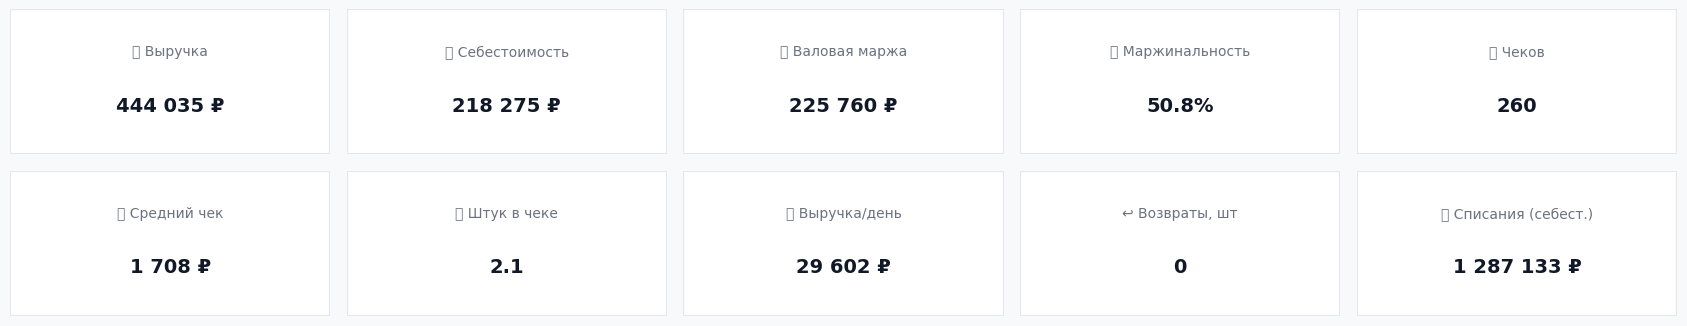

Период: 15 дн. | Списаний на 1 287 133 ₽ = 589.7% от себестоимости продаж | источник: файл «Списания» (оценка: 2 618 407 ₽ по ценам продажи × 49% себест.)
ℹ️ Суммы в файле «Списания» взяты по ценам ПРОДАЖИ и пересчитаны в себестоимость — это оценка.
   Чтобы считать точно: выгружайте «Склад → Ведомость по товарам» с типом документа «Списание» (там себестоимость по позициям).


In [58]:
total_rev    = df_s['Выручка'].sum()
total_cost   = df_s['Себестоимость'].sum()
total_margin = total_rev - total_cost
margin_pct   = total_margin / total_rev * 100 if total_rev else np.nan
n_checks     = df_s['check_key'].nunique()
avg_check    = total_rev / n_checks if n_checks else np.nan
items_per_chk = (~df_s['Возврат']).sum() / n_checks if n_checks else np.nan
days_span    = (df_s['Дата'].max().normalize() - df_s['Дата'].min().normalize()).days + 1
ret_qty      = df_s.loc[df_s['Возврат'], 'Кол-во'].abs().sum()
sold_qty     = df_s.loc[~df_s['Возврат'], 'Кол-во'].sum()
writeoff     = docs_f[docs_f['Это_списание']]
wo_sum       = float(writeoff['Расход (себест.)'].sum())
wo_source    = 'Движение товаров (по себестоимости)'
wo_retail    = False                      # True = суммы списаний пересчитаны из розничных
_wraw = 0.0
if W_DOCS is not None:
    _wraw = max(_wraw, float(W_DOCS['Сумма'].sum(skipna=True)))
if W_LINES is not None:
    _wraw = max(_wraw, float(W_LINES['Сумма'].sum(skipna=True)))
if wo_sum == 0 and _wraw > 0:   # берём из файла «Списания» (там суммы по ценам продажи)
    cost_share = total_cost / max(total_rev, 1)
    if WO_AMOUNT_IS_RETAIL:
        # В списке документов Бизнес.Ру сумма — это обычно РОЗНИЧНАЯ стоимость.
        # Пересчитываем в себестоимость через среднюю долю себестоимости в выручке.
        wo_sum = _wraw * cost_share
        wo_retail = True
        wo_source = f'файл «Списания» (оценка: {rub(_wraw)} по ценам продажи × {cost_share*100:.0f}% себест.)'
    else:
        wo_sum = _wraw
        wo_source = 'файл «Списания» (как в выгрузке)'
elif wo_sum == 0 and (W_DOCS is not None or W_LINES is not None):
    print('⚠️ Файл «Списания» прочитан, но колонка с суммой пустая — проверьте выгрузку.')

# --- Проверка здравого смысла: ловим ошибки единиц измерения / не тот файл ---
if (pd.notna(margin_pct) and (margin_pct > 85 or margin_pct < 0)) or (pd.notna(avg_check) and avg_check > 30000):
    print('🚩 ПОДОЗРИТЕЛЬНЫЕ ЦИФРЫ: маржа %.0f%%, средний чек %s. Для цветочной розницы типично 40–70%% и 800–5000 ₽.' % (margin_pct, rub(avg_check)))
    print('   Проверьте: (1) файл «Продажи» за тот же период; (2) нет ли оптовых/крупных документов; (3) колонки цены/суммы не перепутаны.')
kpis = [('💰 Выручка', rub(total_rev)), ('📉 Себестоимость', rub(total_cost)),
        ('🟢 Валовая маржа', rub(total_margin)), ('📊 Маржинальность', pct(margin_pct)),
        ('🧾 Чеков', num_fmt(n_checks)), ('🎯 Средний чек', rub(avg_check)),
        ('📦 Штук в чеке', f'{items_per_chk:.1f}'), ('📈 Выручка/день', rub(total_rev/days_span)),
        ('↩️ Возвраты, шт', num_fmt(ret_qty)),
        ('🗑 Списания (себест.)', rub(wo_sum)),
        ]
fig, axes = plt.subplots(2, 5, figsize=(17, 3.4))
for ax, (t, v) in zip(axes.ravel(), kpis):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0,0),1,1, transform=ax.transAxes, fc='white', ec='#E5E7EB', lw=1.5))
    ax.text(.5,.68,t,ha='center',fontsize=10,color='#6B7280',transform=ax.transAxes)
    ax.text(.5,.3,v,ha='center',fontsize=14,fontweight='bold',color='#111827',transform=ax.transAxes)
plt.tight_layout(); plt.show()
print(f'Период: {days_span} дн. | Списаний на {rub(wo_sum)} = {wo_sum/total_cost*100 if total_cost else 0:.1f}% от себестоимости продаж | источник: {wo_source}')
if wo_retail:
    print('ℹ️ Суммы в файле «Списания» взяты по ценам ПРОДАЖИ и пересчитаны в себестоимость — это оценка.')
    print('   Чтобы считать точно: выгружайте «Склад → Ведомость по товарам» с типом документа «Списание» (там себестоимость по позициям).')

<a id='шаг8'></a>
# 8. 📈 Динамика выручки и маржи по дням

Столбики — выручка конкретного дня, линия — скользящее среднее за 7 дней (сглаживает «пилу» выходных). Провалы — закрытые дни/неполная выгрузка; пики — праздники и суббота-воскресенье.

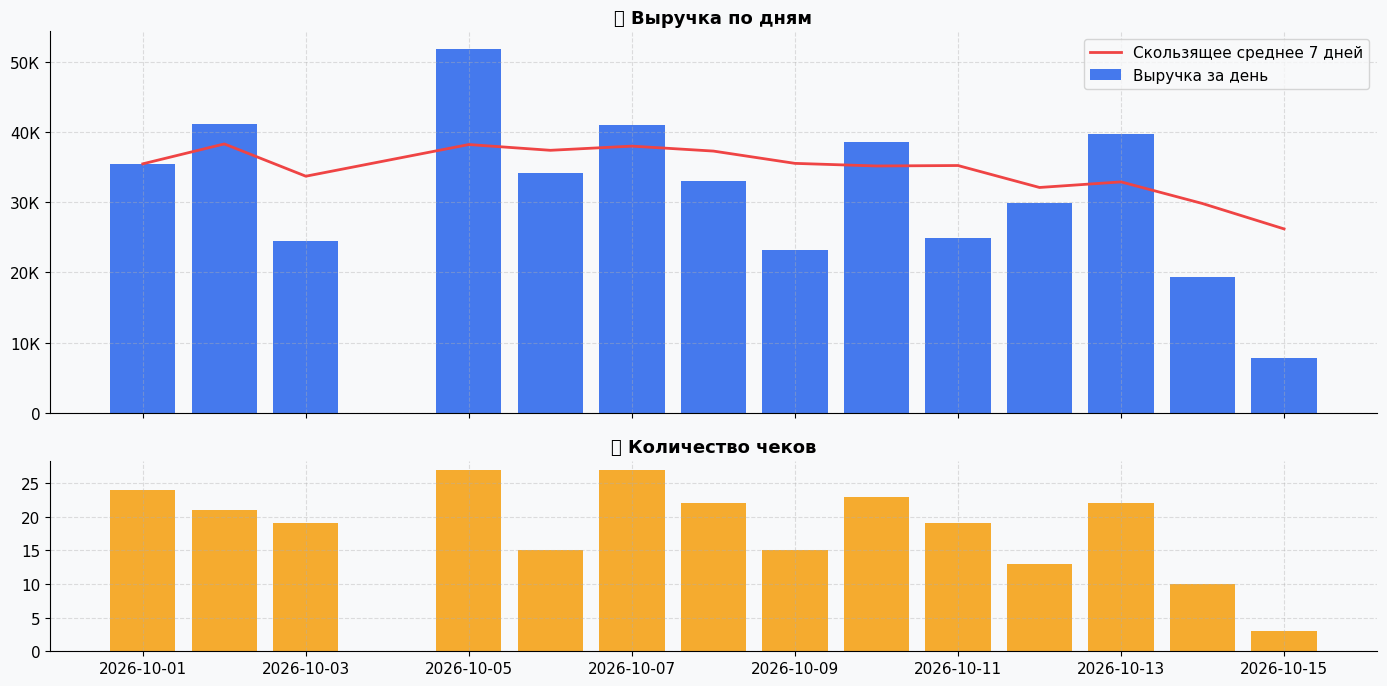

In [59]:
daily = df_s.groupby(df_s['Дата'].dt.normalize()).agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
    Чеков=('check_key','nunique'), Штук=('Кол-во','sum')).reset_index().rename(columns={'Дата':'День'})
daily['MA7'] = daily['Выручка'].rolling(7, min_periods=1).mean()

fig, axes = plt.subplots(2,1, figsize=(14,7), sharex=True, gridspec_kw={'height_ratios':[2,1]})
ax = axes[0]
ax.bar(daily['День'], daily['Выручка'], color=PALETTE[0], alpha=.85, label='Выручка за день')
ax.plot(daily['День'], daily['MA7'], color=PALETTE[3], lw=2, label='Скользящее среднее 7 дней')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
ax.set_title('💸 Выручка по дням'); ax.legend()
ax2 = axes[1]
ax2.bar(daily['День'], daily['Чеков'], color=PALETTE[2], alpha=.85)
ax2.set_title('🧾 Количество чеков');
plt.tight_layout(); plt.show()

<a id='шаг9'></a>
# 9. 🗓 Дни недели и часы работы

Зачем: планирование смен и закупок. Тепловая карта «день × час» подсказывает, в какие часы нужны два флориста, а в какие можно одного.

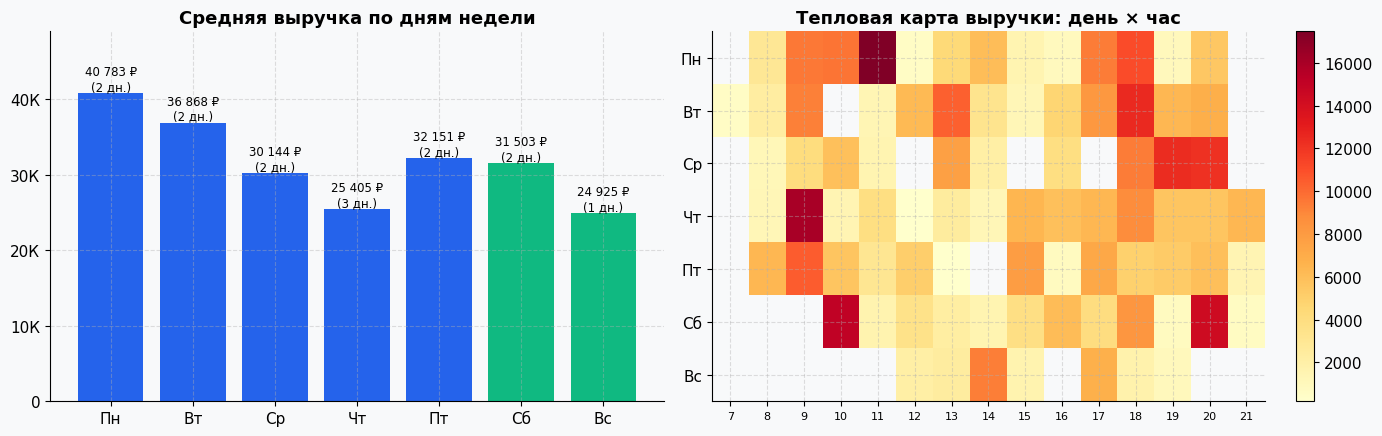

In [60]:
daily['День недели'] = daily['День'].dt.dayofweek
has = daily[daily['Чеков']>0]
dow = has.groupby('День недели').agg(Выручка=('Выручка','mean'), Чеков=('Чеков','mean'), Дней=('Выручка','size'))
dow = dow.reindex(range(7)).fillna(0)

fig, axes = plt.subplots(1,2, figsize=(14,4.5))
ax = axes[0]
cols = [PALETTE[1] if d in (5,6) else PALETTE[0] for d in dow.index]
bars = ax.bar(DAYS_RU, dow['Выручка'], color=cols)
for b,v,n in zip(bars, dow['Выручка'], dow['Дней']):
    ax.text(b.get_x()+b.get_width()/2, v, f'{rub(v)}\n({int(n)} дн.)', ha='center', va='bottom', fontsize=8.5)
ax.set_title('Средняя выручка по дням недели'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
ax.set_ylim(0, dow['Выручка'].max()*1.2 if dow['Выручка'].max()>0 else 1)

hc = df_s[df_s['Час'].notna()].copy(); hc['hour']=hc['Час'].astype(int); hc['wd']=hc['Дата'].dt.dayofweek
pivot = hc.pivot_table(index='wd', columns='hour', values='Выручка', aggfunc='sum').reindex(range(7))
hours = pivot.columns
hm = axes[1].imshow(pivot.values, cmap='YlOrRd', aspect='auto')
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(DAYS_RU)
axes[1].set_xticks(range(len(hours))); axes[1].set_xticklabels([str(h) for h in hours], fontsize=8)
axes[1].set_title('Тепловая карта выручки: день × час')
plt.colorbar(hm, ax=axes[1], fraction=.05)
plt.tight_layout(); plt.show()

<a id='шаг10'></a>
# 10. 🎉 Праздники — главные пики цветочного бизнеса

8 марта, 14 февраля, День матери, выпускные, 1 сентября, Новый год. Множитель «×N к обычному дню» — это ответ на вопрос «сколько цветов закупать»: обычно держат ×2–3 от пикового дня недели за 1–2 дня до праздника.

In [61]:
def holidays_for_year(y):
    nov30 = pd.Timestamp(y,11,30)
    mothers = nov30 - pd.Timedelta(days=(nov30.dayofweek + 1) % 7)   # последнее воскресенье ноября
    return {'14 февраля': (pd.Timestamp(y,2,10), pd.Timestamp(y,2,14)),
            '23 февраля': (pd.Timestamp(y,2,21), pd.Timestamp(y,2,23)),
            '8 марта':    (pd.Timestamp(y,3,2),  pd.Timestamp(y,3,8)),
            'День матери':(mothers - pd.Timedelta(days=4), mothers),
            '1 сентября': (pd.Timestamp(y,8,30), pd.Timestamp(y,9,1)),
            'Новый год':  (pd.Timestamp(y,12,26), pd.Timestamp(y,12,31))}

yrs = sorted(set(df_s['Дата'].dt.year))
hol_ranges = {name:(a,b) for y in yrs for name,(a,b) in holidays_for_year(y).items()}
avg_day = daily.loc[daily['Чеков']>0,'Выручка'].mean()
rows=[]
for name,(a,b) in hol_ranges.items():
    win = daily[(daily['День']>=a)&(daily['День']<=b)]
    if len(win):
        rows.append({'Праздник': f'{name} {a.year}', 'Выручка': win['Выручка'].sum(),
                     'Дней': len(win), 'Выручка/день': win['Выручка'].sum()/len(win)})
hol = pd.DataFrame(rows) if rows else pd.DataFrame(columns=['Праздник','Выручка','Дней','Выручка/день'])
if len(hol):
    hol = hol.sort_values('Выручка', ascending=False)
    fig, ax = plt.subplots(figsize=(11, max(3, .5*len(hol))))
    bars = ax.barh(hol['Праздник'][::-1], hol['Выручка/день'][::-1], color=PALETTE[5])
    for i,(v,base) in enumerate(zip(hol['Выручка/день'][::-1], hol['Выручка/день'][::-1]/avg_day)):
        ax.text(v, i, f'  {rub(v)}  (×{base:.1f} к обычному дню)', va='center', fontsize=9)
    ax.set_title(f'🎉 Средняя выручка в день праздника против обычного дня ({rub(avg_day)})')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); ax.set_xlim(0, hol['Выручка/день'].max()*1.45)
    plt.tight_layout(); plt.show()
    display(hol.reset_index(drop=True))
else:
    print('ℹ️ В выбранном периоде нет праздничных окон.')

ℹ️ В выбранном периоде нет праздничных окон.


<a id='шаг11'></a>
# 11. 🏆 ABC, XYZ и матрицы ABC×XYZ и BCG

**ABC** (принцип Парето): класс A — товары, дающие первые 80% выручки (обычно 20% ассортимента), B — следующие 15%, C — «хвост» 5%.
**XYZ** — стабильность спроса по неделям (CV = коэффициент вариации): X — стабильны (CV≤50%), Y — колеблются, Z — непредсказуемы.
**Матрица ABC×XYZ**: AX — «звёзды», всегда в наличии; CZ — «хвост», выводите из ассортимента.
**BCG** — взгляд со стороны роста: доля товара в выручке магазина × рост продаж (последняя половина периода против первой).

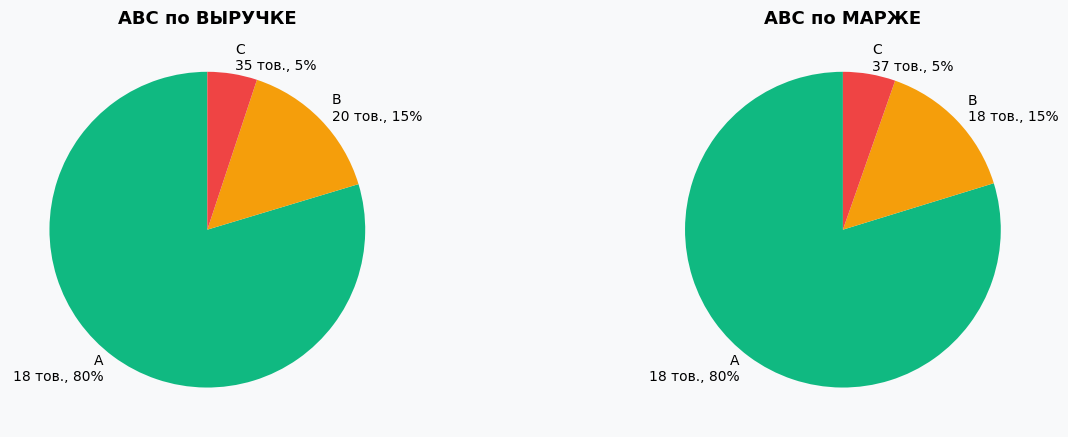

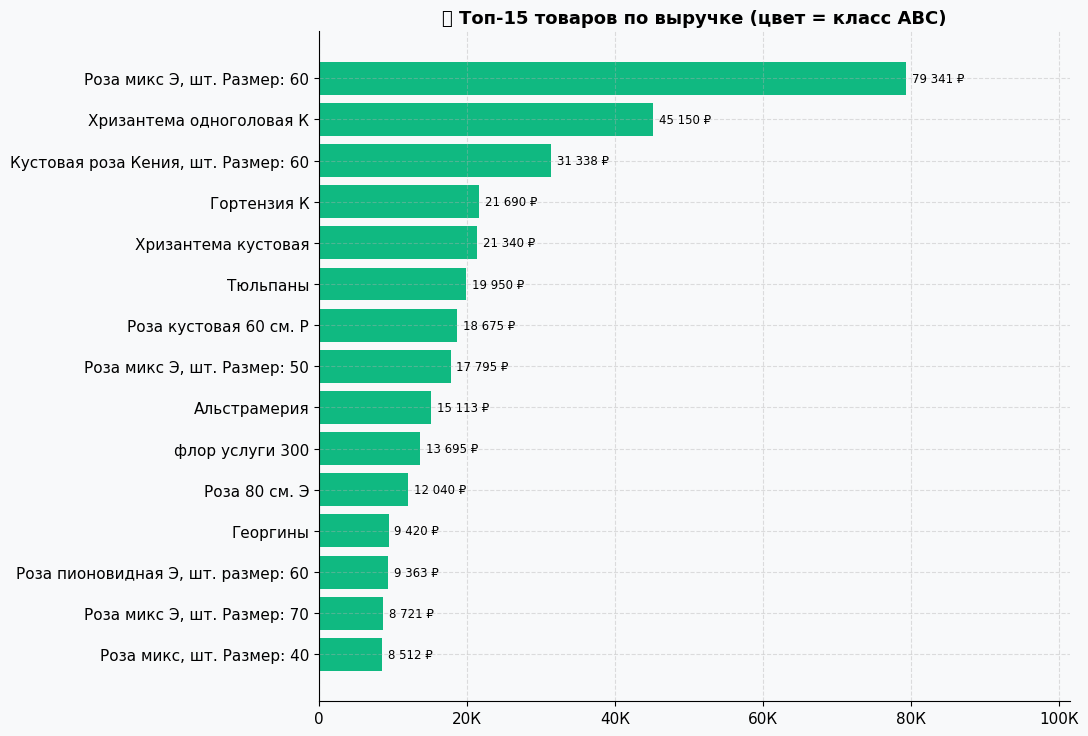

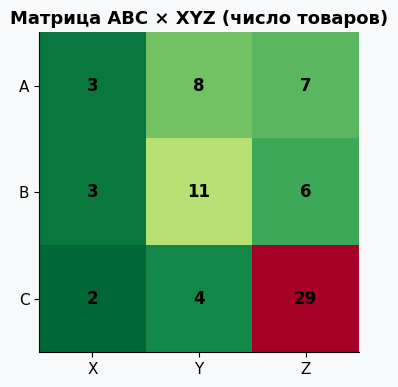

AX — «звёзды» (всегда в наличии), CZ — «хвост» (выводить из ассортимента).


Класс XYZ,X,Y,Z
Класс,,,
A,3,8,7
B,3,11,6
C,2,4,29


In [62]:
def abc_table(data, value_col):
    t = data.groupby('Товар').agg(Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
                                  Продано=('Кол-во','sum'), Чеков=('check_key','nunique')).reset_index()
    t = t.sort_values(value_col, ascending=False).reset_index(drop=True)
    t['Доля %'] = t[value_col]/t[value_col].sum()*100
    t['Накопл %'] = t['Доля %'].cumsum()
    t['Класс'] = np.where(t['Накопл %']<=80,'A', np.where(t['Накопл %']<=95,'B','C'))
    return t

abc_rev   = abc_table(df_s, 'Выручка')
abc_marg  = abc_table(df_s, 'Маржа')

fig, axes = plt.subplots(1,2, figsize=(14,4.5))
for ax, t, ttl in [(axes[0], abc_rev,'ABC по ВЫРУЧКЕ'), (axes[1], abc_marg,'ABC по МАРЖЕ')]:
    # группировка с reset_index: класс становится обычным столбцом, а не индексом —
    # так код работает в любых версиях pandas (в новых int-индексация по метке ломается)
    g = t.groupby('Класс', observed=True).agg(Товаров=('Товар','size'),
                                              Доля=('Доля %','sum')).reset_index()
    labels = [f'{row["Класс"]}\n{int(row["Товаров"])} тов., {row["Доля"]:.0f}%'
              for _, row in g.iterrows()]
    ax.pie(g['Доля'], labels=labels,
           colors=[ABC_COLORS[k] for k in g['Класс']], startangle=90, textprops={'fontsize':10})
    ax.set_title(ttl)
plt.tight_layout(); plt.show()

top = abc_rev.head(TOP_N)
fig, ax = plt.subplots(figsize=(11, .4*len(top)+1.5))
barh_labels(ax, top['Товар'], top['Выручка'], [ABC_COLORS[c] for c in top['Класс']])
ax.invert_yaxis(); ax.set_title(f'🏆 Топ-{TOP_N} товаров по выручке (цвет = класс ABC)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); plt.tight_layout(); plt.show()

# XYZ по неделям
wk = (df_s.assign(Неделя=df_s['Дата'] - pd.to_timedelta(df_s['Дата'].dt.dayofweek, unit='D'))
        .pivot_table(index='Товар', columns='Неделя', values='Кол-во', aggfunc='sum').fillna(0))
xyz = pd.DataFrame({'средн': wk.mean(axis=1), 'cv': (wk.std(axis=1)/wk.mean(axis=1)*100)})
xyz['Класс XYZ'] = np.where(xyz['cv']<=50,'X', np.where(xyz['cv']<=100,'Y','Z'))
xyz.loc[xyz['средн']<=0,'Класс XYZ'] = 'Z'
mat = abc_rev[['Товар','Класс']].merge(xyz[['Класс XYZ']], left_on='Товар', right_index=True, how='left')
mat['Класс XYZ'] = mat['Класс XYZ'].fillna('Z')
ct = pd.crosstab(mat['Класс'], mat['Класс XYZ'])
fig, ax = plt.subplots(figsize=(6,4))
ax.imshow(ct.values, cmap='RdYlGn_r'); ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j,i,ct.values[i,j],ha='center',va='center',fontsize=12,fontweight='bold')
ax.set_title('Матрица ABC × XYZ (число товаров)'); ax.grid(False)
plt.tight_layout(); plt.show()
print('AX — «звёзды» (всегда в наличии), CZ — «хвост» (выводить из ассортимента).')
display(ct)

## 11.1 BCG-матрица (рост × доля) — из flowers_report.ipynb

Делим период пополам: «доля» — сколько выручки даёт товар сейчас, «рост» — как изменились его продажи во второй половине против первой. **Звёзды** (доля↑ рост↑) — не трогать; **Дойные коровы** — стабильные кормильцы; **Вопросительные знаки** — растут, но малы (поддержать рекламой); **Собаки** — падают и малы (выводить).

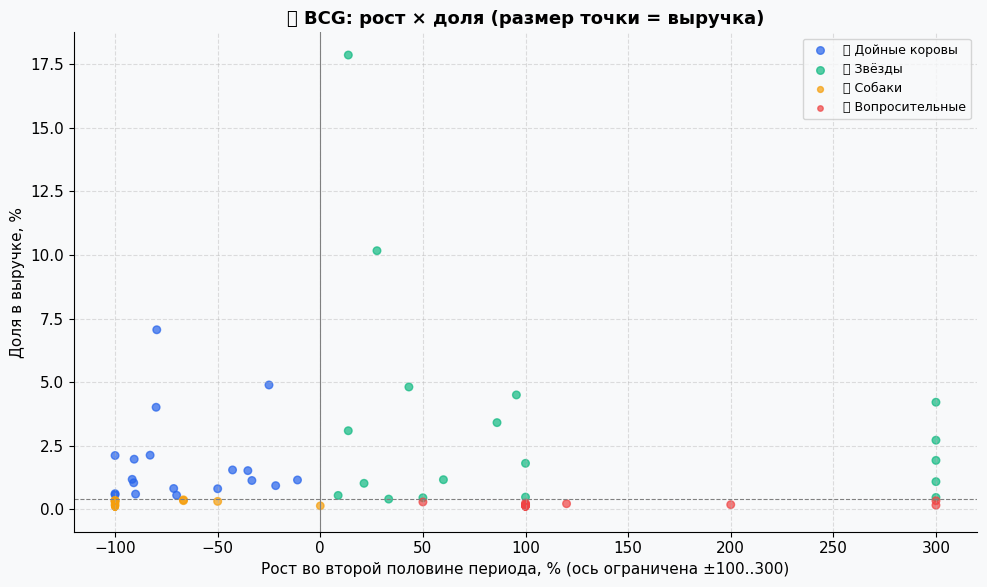

🐕 «Собаки» (малая доля и падение): 16 товаров на 12 422 ₽ — кандидаты на вывод из ассортимента


,Доля %,Рост %,Всего
Товар,,,
Писташ банч,0.03,-100.0,120.0
Аспидистра,0.03,-100.0,150.0
Подарочный пакет L,0.05,-100.0,200.0
Брасика,0.06,-100.0,250.0
Леукосперум,0.07,-100.0,300.0
Сумки маленькие,0.10,-100.0,427.5
Гвоздика кустовая,0.10,-100.0,450.0
Дельфиниум,0.11,-100.0,500.0
Оазис,0.13,0.0,575.0


In [63]:
dates_sorted = df_s['Дата'].sort_values()
mid = dates_sorted.iloc[len(dates_sorted)//2]
pm_b = df_s.groupby('Товар').agg(Всего=('Выручка','sum'),
                                 Первая=('Выручка', lambda s: s[df_s.loc[s.index,'Дата']<=mid].sum()),
                                 Вторая=('Выручка', lambda s: s[df_s.loc[s.index,'Дата']>mid].sum()))
pm_b['Доля %'] = pm_b['Всего']/pm_b['Всего'].sum()*100
pm_b['Рост %'] = np.where(pm_b['Первая']>0, (pm_b['Вторая']/pm_b['Первая']-1)*100, np.where(pm_b['Вторая']>0, 100, 0))
med_share = pm_b['Доля %'].median(); med_growth = 0
def bcg(r):
    hi_s = r['Доля %'] >= med_share; hi_g = r['Рост %'] > med_growth
    return '⭐ Звёзды' if hi_s and hi_g else '🐄 Дойные коровы' if hi_s else '❓ Вопросительные' if hi_g else '🐕 Собаки'
pm_b['BCG'] = pm_b.apply(bcg, axis=1)
fig, ax = plt.subplots(figsize=(10,6))
for grp, col in zip(pm_b['BCG'].unique(), PALETTE):
    q = pm_b[pm_b['BCG']==grp]
    ax.scatter(q['Рост %'].clip(-100,300), q['Доля %'], s=q['Всего'].clip(10,600)/20, alpha=.7, label=grp, color=col)
ax.axvline(0, color='gray', lw=.8); ax.axhline(med_share, color='gray', lw=.8, ls='--')
ax.set_xlabel('Рост во второй половине периода, % (ось ограничена ±100..300)'); ax.set_ylabel('Доля в выручке, %')
ax.set_title('🧭 BCG: рост × доля (размер точки = выручка)'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
dogs = pm_b[pm_b['BCG']=='🐕 Собаки'].sort_values('Всего')
print(f'🐕 «Собаки» (малая доля и падение): {len(dogs)} товаров на {rub(dogs["Всего"].sum())} — кандидаты на вывод из ассортимента')
display(dogs[['Доля %','Рост %','Всего']].head(10).round(2))

<a id='шаг12'></a>
# 12. 📂 Категории товаров

Категории определяются автоматически по названию (розы / хризантемы / горшечные / зелень / упаковка / услуги / прочая срезка). Правая картинка — «карта кормильцев»: по горизонтали деньги, по вертикали — маржинальность. Идеал — правый верхний угол.

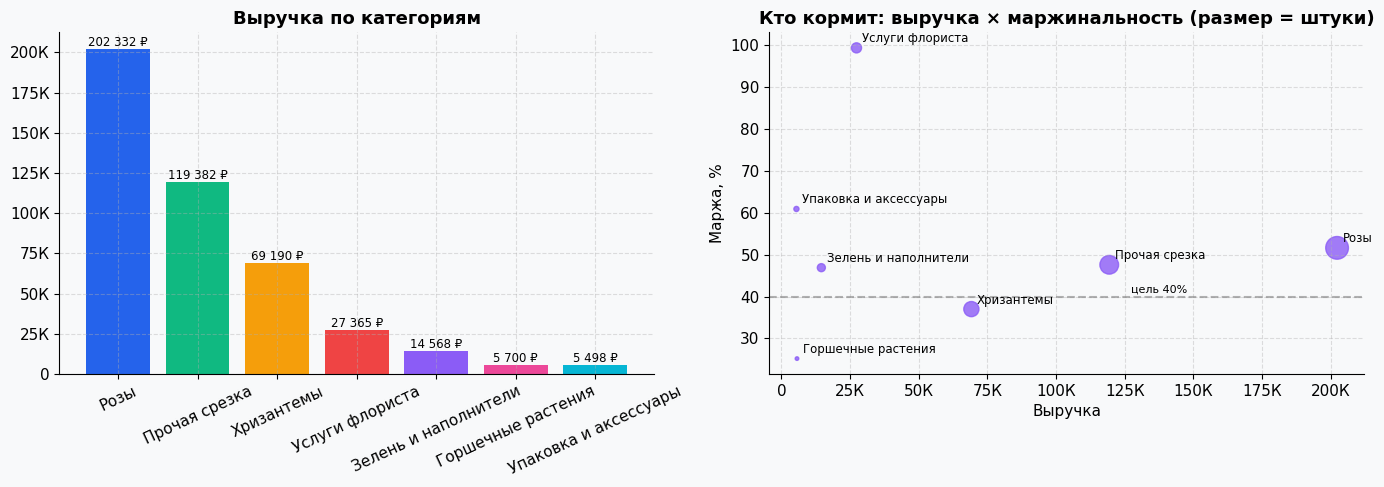

,Категория,Выручка,Маржа,Продано,Чеков,Маржа %
3,Розы,202331.9,104494.4,991.0,120,51.6
2,Прочая срезка,119382.5,56827.6,543.0,89,47.6
6,Хризантемы,69190.0,25611.6,357.0,82,37.0
5,Услуги флориста,27365.0,27206.0,159.0,80,99.4
1,Зелень и наполнители,14568.0,6834.6,101.0,28,46.9
0,Горшечные растения,5700.0,1436.0,11.0,7,25.2
4,Упаковка и аксессуары,5497.5,3349.9,41.0,25,60.9


In [64]:
cat = df_s.groupby('Категория').agg(Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
                                    Продано=('Кол-во','sum'), Чеков=('check_key','nunique')).reset_index()
cat['Маржа %'] = cat['Маржа']/cat['Выручка']*100
cat = cat.sort_values('Выручка', ascending=False)
fig, axes = plt.subplots(1,2, figsize=(14,5))
ax = axes[0]
bars = ax.bar(cat['Категория'], cat['Выручка'], color=PALETTE[:len(cat)])
for b,v in zip(bars,cat['Выручка']):
    ax.text(b.get_x()+b.get_width()/2, v, rub(v), ha='center', va='bottom', fontsize=8.5)
ax.set_title('Выручка по категориям'); ax.tick_params(axis='x', rotation=25)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
ax = axes[1]
ax.scatter(cat['Выручка'], cat['Маржа %'], s=cat['Продано'].clip(20,800)/3, color=PALETTE[4], alpha=.8)
for _,r in cat.iterrows():
    ax.annotate(r['Категория'], (r['Выручка'], r['Маржа %']), fontsize=8.5, xytext=(4,4), textcoords='offset points')
ax.axhline(MARGIN_TARGET, ls='--', color='gray', alpha=.6); ax.text(ax.get_xlim()[1]*.6, MARGIN_TARGET+1, f'цель {MARGIN_TARGET}%', fontsize=8)
ax.set_xlabel('Выручка'); ax.set_ylabel('Маржа, %'); ax.set_title('Кто кормит: выручка × маржинальность (размер = штуки)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()
display(cat.round(1))

<a id='шаг13'></a>
# 13. 🛒 Структура чека и Market Basket («что покупают вместе»)

**Market Basket** ищет пары товаров, которые покупают вместе чаще, чем случайно:
• *Поддержка* — доля чеков с этой парой; • *Lift* — во сколько раз чаще, чем если бы покупки не зависели друг от друга (Lift>1 — реальная связка); • *Конверсия A→B* — если взяли A, то с вероятностью X% возьмут и B → готовые скрипты допродажи: «к розам — эвкалипт, к букету — открытку».

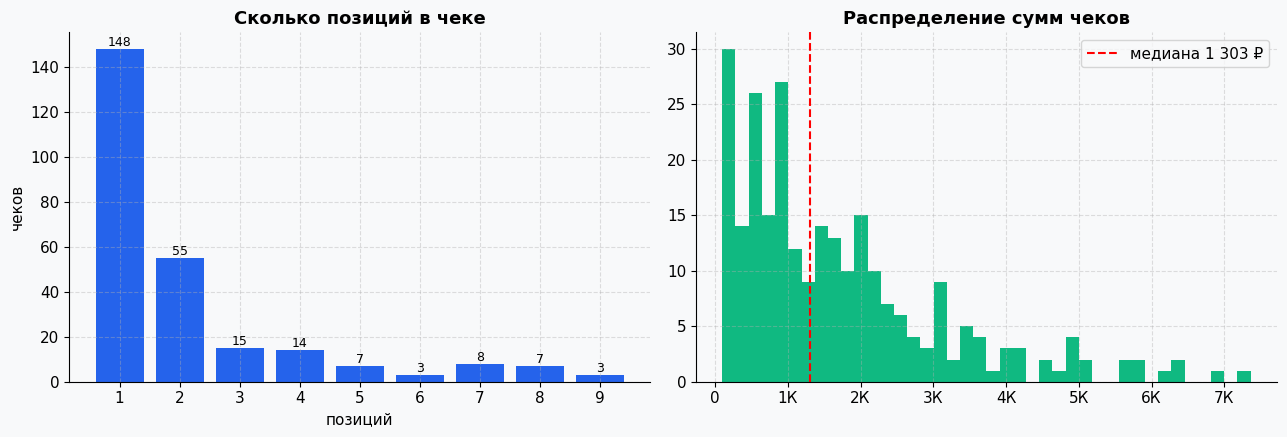

✅ Пар найдено: 8. Топ-10 связок:


,Товар A,Товар B,Чеков с парой,Поддержка %,Lift,Конф. A→B,Конф. B→A
0,Оазис,Сумки средние,6,2.37,28.11,66.67,100.00
3,Вакс-флаур,Гортензия К,7,2.77,8.01,53.85,41.18
6,Оазис,Хризантема кустовая,6,2.37,5.44,66.67,19.35
1,Альстрамерия,Гортензия К,6,2.37,4.06,27.27,35.29
4,Вакс-флаур,Хризантема кустовая,6,2.37,3.77,46.15,19.35
2,Альстрамерия,Хризантема кустовая,9,3.56,3.34,40.91,29.03
5,Гортензия К,Хризантема кустовая,5,1.98,2.40,29.41,16.13
7,"Кустовая роза Кения, шт. Размер: 60",Хризантема кустовая,5,1.98,2.15,26.32,16.13


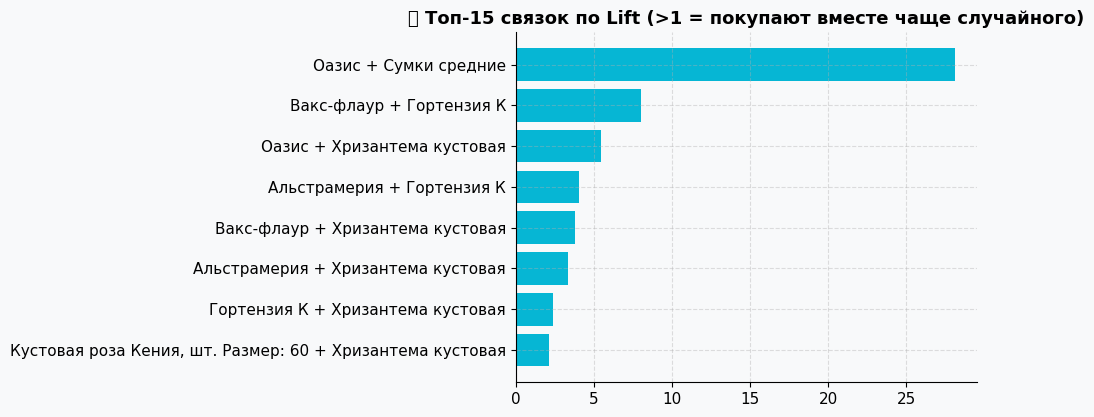

In [65]:
bk_src = df_s[~df_s['Категория'].isin(EXCLUDE_FROM_BASKET)]
chk = df_s.groupby('check_key').agg(Выручка=('Выручка','sum'), Позиций=('Товар','count'), Штук=('Кол-во','sum'))
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
sz = chk['Позиций'].clip(upper=10).value_counts().sort_index()
axes[0].bar(sz.index.astype(str), sz.values, color=PALETTE[0])
axes[0].set_title('Сколько позиций в чеке'); axes[0].set_xlabel('позиций'); axes[0].set_ylabel('чеков')
for i,(x,y) in enumerate(zip(sz.index.astype(str), sz.values)):
    axes[0].text(i, y, int(y), ha='center', va='bottom', fontsize=9)
dist = chk['Выручка']
axes[1].hist(dist[dist>0], bins=40, color=PALETTE[1])
axes[1].axvline(dist.median(), color='red', ls='--', label=f'медиана {rub(dist.median())}')
axes[1].set_title('Распределение сумм чеков'); axes[1].legend(); axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

baskets = bk_src.groupby('check_key')['Товар'].apply(set)
n_b = len(baskets)
cnt = Counter(); pair_cnt = Counter()
for b in baskets:
    cnt.update(b)
    for p in combinations(sorted(b), 2): pair_cnt[p]+=1
rows=[]
for (a,b),c in pair_cnt.items():
    if c < MIN_PAIR_COUNT: continue
    sup = c/n_b; lift = c*n_b/(cnt[a]*cnt[b])
    conf_ab = c/cnt[a]; conf_ba = c/cnt[b]
    if sup >= MIN_SUPPORT and lift > 1:
        rows.append({'Товар A':a,'Товар B':b,'Чеков с парой':c,'Поддержка %':sup*100,
                     'Lift':lift,'Конф. A→B':conf_ab*100,'Конф. B→A':conf_ba*100})
mb = pd.DataFrame(rows, columns=['Товар A','Товар B','Чеков с парой','Поддержка %','Lift','Конф. A→B','Конф. B→A']).sort_values('Lift', ascending=False)
if len(mb):
    print(f'✅ Пар найдено: {len(mb)}. Топ-10 связок:')
    display(mb.head(10).round(2))
    fig, ax = plt.subplots(figsize=(10, .35*min(15,len(mb))+1.5))
    t = mb.head(15)[::-1]
    ax.barh([f'{a} + {b}' for a,b in zip(t['Товар A'],t['Товар B'])], t['Lift'], color=PALETTE[6])
    ax.set_title('🧺 Топ-15 связок по Lift (>1 = покупают вместе чаще случайного)')
    plt.tight_layout(); plt.show()
else:
    print('ℹ️ Заметных пар нет (мало многопозиционных чеков или маленький период).')

<a id='шаг13b'></a>
## 13.1 👥 RFM-сегментация клиентов — «кто приносит деньги и кто уходит» *(добавлено из блокнота «Анализ_цветочного_магазина_БизнесРу.ipynb»)*

**Что это:** каждому клиенту ставим 3 оценки по 5 баллов: **R** (Recency — как давно покупал), **F** (Frequency — как часто), **M** (Money — сколько потратил). Комбинация даёт сегменты: 💎 «Лучшие», 🌱 «Новые», 🚨 «Уходят», 💤 «Потерянные», 🙂 «Середнячки».

**Зачем это новичку:** вернуть «уходящего» постоянного клиента в 5–7 раз дешевле, чем найти нового. Это самый быстрый способ поднять выручку без закупок: обзвон + промокод.

**Где взять данные:** Бизнес.Ру → **CRM → Клиенты и партнёры** → «Вывод → Таблицы Excel» → положить в `data/` (файл со словом «клиент»). Если файла нет, блокнот попробует вытащить имена клиентов прямо из строк «Движения товаров»; если известных клиентов меньше `RFM_MIN_CLIENTS` — раздел честно пропустится (а не соврёт).

**Как читать:** доля выручки сегмента «Лучшие» (обычно 20% клиентов дают 60%+ денег — закон Парето). Список «🚨 Уходят (были лучшими!)» — план действий на эту неделю.


In [66]:
# ---------- 13.1 RFM: кто наши клиенты и кто уходит ----------
cli_col = pd.Series(index=df_s.index, dtype=object)
has_cli = ('Клиент' in df_s.columns) and np.ndim(df_s['Клиент'].values) == 1
if has_cli and pd.Series(df_s['Клиент'].values).notna().any():
    cli_col = pd.Series(df_s['Клиент'].values, index=df_s.index)
    print('👤 Клиенты распознаны из строк документов «Движения товаров»')
elif len(globals().get('CLI_BY_DOC', {})):
    hit = df_s['check_key'].astype(str).isin(set(CLI_BY_DOC))
    cli_col[hit] = df_s.loc[hit, 'check_key'].astype(str).map(CLI_BY_DOC).values
    print(f'👤 Клиенты подтянуты из файла «Реализации» ({int(hit.sum())} позиций чеков)')
elif 'Клиенты' in extra:
    cb = extra['Клиенты'].copy()
    ncol = next((c for c in cb.columns if any(w in norm_name(c) for w in
               ['фио','клиент','партнер','наименован','name'])), None)
    rcol = next((c for c in cb.columns if any(w in norm_name(c) for w in ['док','заказ','номер','чек'])), None)
    if ncol and rcol:
        link = cb.assign(_n=cb[ncol].astype(str).str.strip(), _d=cb[rcol].astype(str).str.strip())
        link = link[link['_n'].ne('') & link['_n'].str.lower().ne('nan')]
        mp = link.drop_duplicates('_d').set_index('_d')['_n']
        hit = df_s['check_key'].astype(str).isin(set(mp.index))
        cli_col[hit] = df_s.loc[hit, 'check_key'].astype(str).map(mp.to_dict()).values
        print(f'👤 Клиенты подтянуты по номерам документов из файла «Клиенты» ({link["_n"].nunique()} имён)')
df_s['Клиент'] = cli_col.values
share_known = df_s.loc[df_s['Клиент'].notna(), 'Выручка'].sum() / max(df_s['Выручка'].sum(), 1)
print(f'🧾 Выручка с привязкой к клиенту: {share_known*100:.0f}%  '
      f'(если <30% — приучайте кассиров спрашивать телефон/карту лояльности: без этого CRM слепа)')

rfm = None
n_cli = df_s['Клиент'].nunique()
if n_cli >= RFM_MIN_CLIENTS:
    now = _dmax.normalize() + pd.Timedelta(days=1)
    cl = df_s[df_s['Клиент'].notna()]
    rfm = cl.groupby('Клиент').agg(Последняя_покупка=('Дата','max'), Покупок=('check_key','nunique'),
                                   Потрачено=('Выручка','sum'))
    rfm['Дней_без_нас'] = (now - rfm['Последняя_покупка'].dt.normalize()).dt.days
    rfm['R'] = pd.qcut(rfm['Дней_без_нас'].rank(method='first'), 5, labels=[5,4,3,2,1]).astype(int)
    rfm['F'] = pd.qcut(rfm['Покупок'].rank(method='first', ascending=False), 5, labels=[1,2,3,4,5]).astype(int)
    rfm['M'] = pd.qcut(rfm['Потрачено'].rank(method='first', ascending=False), 5, labels=[1,2,3,4,5]).astype(int)
    def segment(r):
        if r.R >= 4 and r.F >= 4: return '💎 Лучшие'
        if r.R >= 4 and r.F <= 2:  return '🌱 Новые'
        if r.R <= 2 and r.F >= 4:  return '🚨 Уходят (были лучшими!)'
        if r.R <= 2 and r.F <= 2:  return '💤 Потерянные'
        return '🙂 Середнячки'
    rfm['Сегмент'] = rfm.apply(segment, axis=1)
    sg = rfm.groupby('Сегмент').agg(Клиентов=('Потрачено','size'), Выручка=('Потрачено','sum'),
                                    Ср_покупок=('Покупок','mean'), Ср_дней_паузы=('Дней_без_нас','mean')
                                    ).sort_values('Выручка', ascending=False)
    sg['Доля выручки, %'] = sg['Выручка']/sg['Выручка'].sum()*100
    display(sg.style.format({'Выручка': '{:,.0f}', 'Ср_покупок': '{:.1f}',
                             'Ср_дней_паузы': '{:.0f}', 'Доля выручки, %': '{:.0f}'}))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    sg['Доля выручки, %'].sort_values().plot.barh(ax=ax, color=PALETTE[1])
    ax.set_title('Вклад RFM-сегментов в выручку по известным клиентам, %')
    plt.tight_layout(); plt.show()
    rep = (rfm['Покупок'] >= 2).mean()
    churn = rfm[rfm['Сегмент'] == '🚨 Уходят (были лучшими!)']
    print(f'🔁 Повторные покупатели: {rep*100:.0f}% (для цветочной розницы норма 20–35%).')
    if len(churn):
        print(f'📞 «Золотой список» для возврата: {len(churn)} клиентов принесли {rub(churn["Потрачено"].sum())} — '
              f'обзвон/сообщение с промокодом обычно возвращает 10–20% из них.')
    print('💡 Действия: «Лучшим» — закрытая рассылка и приоритет букетов к праздникам; «Новым» — скидка на 2-ю покупку;')
    print('   «Уходящим» — персональный звонок; «Потерянных» — одна массовая акция, дальше не вкладываться.')
else:
    print(f'ℹ️ Известных клиентов всего {n_cli} (<{RFM_MIN_CLIENTS}) — RFM пропускаем. '
          f'Начните привязывать чеки к клиентам в Бизнес.Ру (CRM → Клиенты), и в следующем месяце раздел заработает!')


🧾 Выручка с привязкой к клиенту: 0%  (если <30% — приучайте кассиров спрашивать телефон/карту лояльности: без этого CRM слепа)
ℹ️ Известных клиентов всего 0 (<20) — RFM пропускаем. Начните привязывать чеки к клиентам в Бизнес.Ру (CRM → Клиенты), и в следующем месяце раздел заработает!


<a id='шаг14'></a>
# 14. 💹 Цены и маржа: где теряем деньги

Каждая точка — товар. Красные — маржа <10% (работаем в убыток/в ноль). Отдельно выводим «ходовые, но низкомаржинальные» — именно они съедают прибыль, потому что их много продают по старой цене.

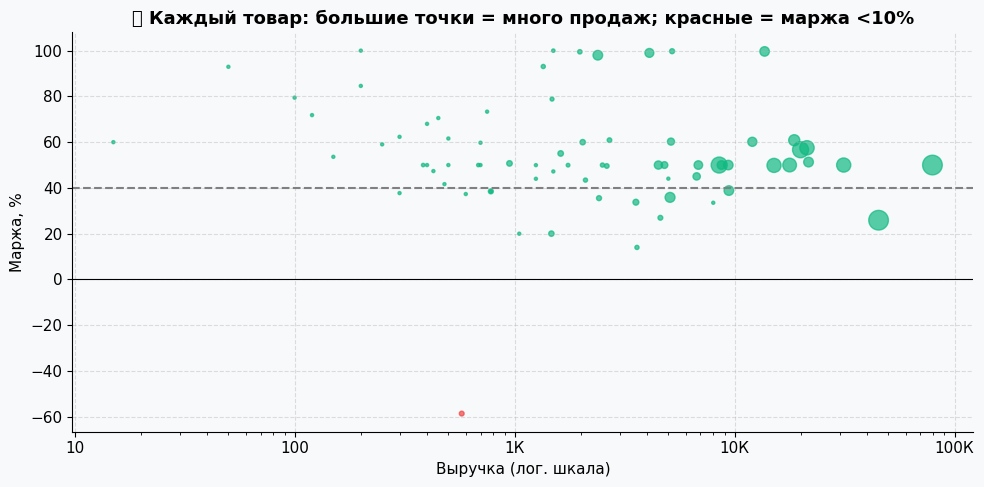

🚨 Товаров с маржой <10% (или отрицательной): 1


,Товар,Выручка,Маржа,Маржа %,Продано,Средняя_цена
31,Оазис,575.0,-337.0,-58.608696,12.0,47.916667


⚠️ Ходовые, но низкомаржинальные (<40%): 8


,Товар,Выручка,Маржа %,Продано
65,Хризантема одноголовая К,45150.0,25.891473,239.0
9,Георгины,9420.0,38.853503,48.0
40,Протея люкс,8000.0,33.527000,4.0
53,Сантини,5090.0,35.874263,51.0
29,Лилия 5+,4600.0,26.956522,12.0
0,Алиум,3600.0,14.000000,9.0
55,Скимия,3560.0,33.764045,18.0
8,Гелиантус,2420.0,35.537190,13.0


In [67]:
pm = df_s[~df_s['Возврат']].groupby('Товар').agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'), Продано=('Кол-во','sum'),
    Себестоимость=('Себестоимость','sum'), Средняя_цена=('Цена продажи','mean')).reset_index()
pm['Маржа %'] = np.where(pm['Выручка']>0, pm['Маржа']/pm['Выручка']*100, np.nan)
pm['Наценка %'] = np.where(pm['Себестоимость']>0, pm['Маржа']/pm['Себестоимость']*100, np.nan)

neg = pm[(pm['Маржа']<0)|(pm['Маржа %']<10)].sort_values('Маржа')
low = pm[(pm['Маржа %']<MARGIN_TARGET)&(pm['Выручка']>pm['Выручка'].quantile(.5))].sort_values('Выручка',ascending=False)

fig, ax = plt.subplots(figsize=(10,5))
samp = pm[pm['Выручка']>0].sample(min(400,(pm['Выручка']>0).sum()), random_state=1)
ax.scatter(samp['Выручка'], samp['Маржа %'], s=samp['Продано'].clip(5,200),
           c=np.where(samp['Маржа %']<10, PALETTE[3], PALETTE[1]), alpha=.7)
ax.axhline(MARGIN_TARGET, ls='--', color='gray'); ax.axhline(0, color='black', lw=.8)
ax.set_xscale('log'); ax.set_xlabel('Выручка (лог. шкала)'); ax.set_ylabel('Маржа, %')
ax.set_title('💹 Каждый товар: большие точки = много продаж; красные = маржа <10%')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

print(f'🚨 Товаров с маржой <10% (или отрицательной): {len(neg)}')
if len(neg): display(neg[['Товар','Выручка','Маржа','Маржа %','Продано','Средняя_цена']].head(10))
print(f'⚠️ Ходовые, но низкомаржинальные (<{MARGIN_TARGET}%): {len(low)}')
if len(low): display(low[['Товар','Выручка','Маржа %','Продано']].head(10))

<a id='шаг15'></a>
# 15. 📦 Склад: «залёжалый» товар и план закупки

**Залёжалый** — лежит на складе, но не продаётся SLOW_DAYS+ дней: деньги заморожены, цветы скоро завянут.
**План закупки** — простая модель: скорость продаж (шт/день за последние COVER_LOOKBACK дней) × COVER_DAYS минус текущий остаток = сколько заказать. Для цветов COVER_DAYS = 3–5 дней — дольше роза не живёт.

In [68]:
last_sale = df_s[~df_s['Возврат']].groupby('Товар')['Дата'].max()
st = stock.merge(last_sale.rename('Последняя продажа'), left_on='Товар', right_index=True, how='left')
_period_days = (_dmax.normalize() - _dmin.normalize()).days + 1
# не продавался вообще за период -> считаем «столько дней, сколько длится период» (а не магическое 9999)
st['Дней без продаж'] = (_dmax - st['Последняя продажа']).dt.days.fillna(_period_days).astype(int)
_slow = min(SLOW_DAYS, _period_days)          # период короче порога — сравниваем с длиной периода
if _period_days < SLOW_DAYS:
    print(f'ℹ️ Период ({_period_days} дн.) короче порога SLOW_DAYS={SLOW_DAYS}: «залежалым» считаем всё, что не продавалось за весь период.')
dead = st[(st['Кон. остаток']>0)&(st['Дней без продаж']>=_slow)].sort_values('Остаток, ₽', ascending=False)
print(f'🧊 Залежалый товар (нет продаж {SLOW_DAYS}+ дн., но лежит на складе): {len(dead)} позиций на {rub(dead["Остаток, ₽"].sum()) if len(dead) else "0 ₽"}')
if len(dead): display(dead[['Товар','Категория','Кон. остаток','Остаток, ₽','Дней без продаж']].head(15))

win_start = _dmax - pd.Timedelta(days=COVER_LOOKBACK-1)
win = df_s[(df_s['Дата']>=win_start)&(~df_s['Возврат'])]
work_days = max(win['Дата'].dt.normalize().nunique(), 1)
speed = win.groupby('Товар')['Кол-во'].sum()/work_days
plan = stock[['Товар','Категория','Кон. остаток']].copy()
plan['Шт/день'] = plan['Товар'].map(speed).fillna(0)
plan['Нужно на %d дн.' % COVER_DAYS] = (plan['Шт/день']*COVER_DAYS).round(0)
plan['Заказать, шт'] = (plan[f'Нужно на {COVER_DAYS} дн.'] - plan['Кон. остаток']).clip(lower=0).round(0)
plan['Цена продажи'] = plan['Товар'].map(df_s.groupby('Товар')['Цена продажи'].mean())
unit_cost_map = unit_cost_by(df_s[~df_s['Возврат']], 'Товар')
plan['Себест./шт'] = plan['Товар'].map(unit_cost_map)
plan['Сумма закупки, ₽'] = plan['Заказать, шт']*plan['Себест./шт'].fillna(0)
buy = plan[(plan['Заказать, шт']>0)&(~plan['Категория'].isin(EXCLUDE_FROM_BASKET))].sort_values('Шт/день', ascending=False)
print(f'🛒 К заказу на {COVER_DAYS} дней: {len(buy)} позиций ориентировочно на {rub(buy["Сумма закупки, ₽"].sum())}')
display(buy[['Товар','Категория','Шт/день','Кон. остаток','Заказать, шт']].head(20))

ℹ️ Период (15 дн.) короче порога SLOW_DAYS=21: «залежалым» считаем всё, что не продавалось за весь период.
🧊 Залежалый товар (нет продаж 21+ дн., но лежит на складе): 160 позиций на 182 335 ₽


,Товар,Категория,Кон. остаток,"Остаток, ₽",Дней без продаж
413,фаленопсис каскад микс 12/50,Горшечные растения,7.0,9520.00,15
44,Астильба,Прочая срезка,101.0,7191.20,15
61,Букет 9 одноголовых хризантем,Хризантемы,7.0,6300.00,15
158,Каллы,Прочая срезка,45.0,5160.00,15
33,антуриум 23/40,Горшечные растения,3.0,4800.00,15
253,Матиола,Прочая срезка,56.0,4525.00,15
97,Гиперекум,Прочая срезка,38.0,3846.60,15
393,Танацетум,Зелень и наполнители,28.0,3811.32,15
159,Каллы высокие,Прочая срезка,31.0,3664.00,15
89,Георгина 12,Прочая срезка,21.0,3659.25,15


🛒 К заказу на 4 дней: 16 позиций ориентировочно на 17 650 ₽


,Товар,Категория,Шт/день,Кон. остаток,"Заказать, шт"
442,Хризантема одноголовая К,Хризантемы,17.071429,43.0,25.0
225,"Кустовая роза Кения, шт. Размер: 60",Розы,7.428571,0.0,30.0
335,"Роза микс Э, шт. Размер: 50",Розы,6.928571,0.0,28.0
345,"Роза пионовидная Э, шт. размер: 60",Розы,3.357143,0.0,13.0
337,"Роза микс Э, шт. Размер: 70",Розы,2.785714,0.0,11.0
339,"Роза микс, шт. Размер: 50",Розы,2.500000,0.0,10.0
98,Гипсофила,Зелень и наполнители,1.857143,0.0,7.0
224,"Кустовая роза Кения, шт. Размер: 50",Розы,0.642857,0.0,3.0
13,Алиум,Горшечные растения,0.642857,0.0,3.0
388,Сумки средние,Упаковка и аксессуары,0.571429,1.0,1.0


<a id='шаг15b'></a>
## 15.1 🌤 Сезонность топовых товаров — «что и когда покупать заранее» *(добавлено из блокнота flowers_report.ipynb)*

**Что это:** тепловая карта «товар × месяц» по топ-12 продажам. Цветочный бизнес живёт сезонами: пионы — май, хризантемы — осень, ёлки и пуансеттия — декабрь.

**Как читать:** яркая клетка = месяц пика товара. Закупаться лучше за 3–4 недели до пика: в разгар сезона поставщики поднимают цены и «выгребают» лучшие сорта. Если истории меньше `SEASON_MONTHS` месяцев — раздел пропустится (это нормально для первого запуска).


In [69]:
# ---------- 15.1 Сезонность топовых товаров ----------
hist_months = df_s.loc[~df_s['Возврат'], 'Дата'].dt.to_period('M').nunique()
season_tbl = pd.DataFrame()
if hist_months >= SEASON_MONTHS and len(abc_rev):
    top_season = abc_rev.head(12)['Товар'].tolist()
    ss = df_s[df_s['Товар'].isin(top_season) & ~df_s['Возврат']]
    piv = ss.pivot_table(index='Товар', columns=ss['Дата'].dt.month, values='Кол-во', aggfunc='sum')
    piv = piv.reindex(top_season).fillna(0)
    _MRU = ['янв','фев','мар','апр','май','июн','июл','авг','сен','окт','ноя','дек']
    piv.columns = [_MRU[m-1] for m in piv.columns]
    fig, ax = plt.subplots(figsize=(12, 4.8))
    im = ax.imshow(piv.values, cmap='Greens', aspect='auto')
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([t[:30] for t in piv.index]); ax.grid(False)
    for _i in range(piv.shape[0]):
        for _j in range(piv.shape[1]):
            ax.text(_j, _i, f'{piv.values[_i, _j]:.0f}', ha='center', va='center', fontsize=8)
    plt.colorbar(im, ax=ax, fraction=.04)
    ax.set_title(f'🌤 Сезонность топ-{len(piv)} товаров: продано (шт) по месяцам | истории: {hist_months} мес.')
    plt.tight_layout(); plt.show()
    month_names = {i: c for i, c in enumerate(piv.columns)}
    season_tbl = pd.DataFrame({'Пик (месяц)': piv.idxmax(axis=1).map(month_names),
                               'Шт в пике': piv.max(axis=1)}).reset_index()
    print('📅 Пики: ' + '; '.join(f'{t[:22]} → {m}' for t, m in zip(season_tbl['Товар'], season_tbl['Пик (месяц)'])))
else:
    print(f'ℹ️ Для карты сезонности нужно ≥{SEASON_MONTHS} месяцев истории (сейчас {hist_months}) — '
          f'расширьте DATE_FROM или выгрузите больший период из Бизнес.Ру.')


ℹ️ Для карты сезонности нужно ≥6 месяцев истории (сейчас 1) — расширьте DATE_FROM или выгрузите больший период из Бизнес.Ру.


<a id='шаг16'></a>
# 16. 🔮 Прогноз выручки на FORECAST_DAYS дней

Честный простой метод: **медиана аналогичного дня недели за последние 8 недель** (цветы продаются «по ритму недели»). Сначала проверяем себя на истории (*backtest*: прогнозируем последние 14 дней и сравниваем с фактом) — и только потом выбираем лучший метод для будущего. Для сложных моделей (Prophet, LightGBM) — см. раздел 21.

ℹ️ Истории меньше 3 недель — backtest пропускаем.


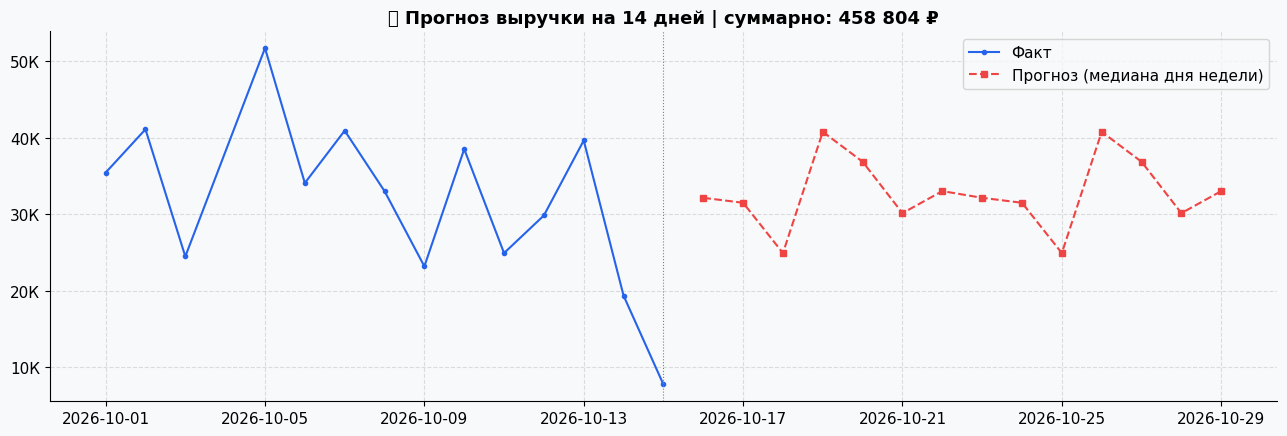

In [70]:
series = daily.set_index('День')['Выручка'].asfreq('D')
hist = series.dropna()

def predict_dow(h, target, weeks=8):
    same = h[(h.index.dayofweek==target.dayofweek) & (h.index >= target-pd.Timedelta(weeks=weeks))]
    if len(same)==0: same = h[h.index.dayofweek==target.dayofweek]
    return same.median() if len(same) else h.mean()

bt_dates = hist.index[-14:] if len(hist) >= 21 else hist.index[:0]
err = {}
if len(bt_dates)==0:
    print('ℹ️ Истории меньше 3 недель — backtest пропускаем.')
for name, fn in [('по дню недели', lambda h,t: predict_dow(h,t)),
                 ('среднее за 28 дн.', lambda h,t: h.tail(28).mean()),
                 ('наивный (вчера)', lambda h,t: h.iloc[-1])]:
    if len(bt_dates) == 0: break
    preds = [fn(hist[hist.index<d], d) for d in bt_dates]
    err[name] = np.mean(np.abs(np.array(preds)-hist.loc[bt_dates].values))
best = min(err, key=err.get) if err else '—'
if err:
    print('📉 Средняя ошибка прогноза (backtest, ₽):', {k: rub(v) for k,v in err.items()}, f'→ лучший: {best}')

future = pd.date_range(series.index.max()+pd.Timedelta(days=1), periods=FORECAST_DAYS, freq='D')
fc = pd.Series([predict_dow(hist,d) for d in future], index=future)
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(hist.index, hist.values, marker='o', ms=3, color=PALETTE[0], label='Факт')
ax.plot(fc.index, fc.values, marker='s', ms=5, color=PALETTE[3], ls='--', label='Прогноз (медиана дня недели)')
ax.axvline(series.index.max(), color='gray', lw=.8, ls=':')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); ax.legend()
ax.set_title(f'🔮 Прогноз выручки на {FORECAST_DAYS} дней | суммарно: {rub(fc.sum())}')
plt.tight_layout(); plt.show()

<a id='шаг17'></a>
# 17. 🕵️ ДЕТЕКТОР ПОТЕРЬ И ХИЩЕНИЙ

Здесь блокнот ищет числовые следы способов №1–№15 из раздела 2:

| Проверка | Какой способ ловит |
|---|---|
| 17.1 Невязки остатков | №11 прямая кража, №2 непробитая продажа, №7 задним числом |
| 17.2 Пики списаний (robust z-score) | №6 ложная порча, №7 списания пачкой |
| 17.3 Списываются ходовые позиции | №6 ложная порча (засохнуть массово могут тюльпаны, а не топ-роза) |
| 17.4 Всплески возвратов, возвраты после 18:00, «нет второй продажи» | №1 минусовка |
| 17.5 Сверка Движение ↔ Касса | №2 непробитая продажа, №15 кража из кассы |
| 17.6 Продажи >15% ниже медианной цены | №3 занижение суммы |
| 17.7 Пересортица (плюс одного = минус другого) | №9 пересортица |

> Помните про «невинные объяснения» — сигналы проверяются в связке с камерой, журналами и инвентаризацией.

🗑 Источник данных о списаниях: файл «Списания» (оценка: 2 618 407 ₽ по ценам продажи × 49% себест.), всего за период: 81 645 ₽
🗑 Списания: всего 81 645 ₽ за 9 дн., типичный день 3 996 ₽, максимум 32 816 ₽ (04.10)


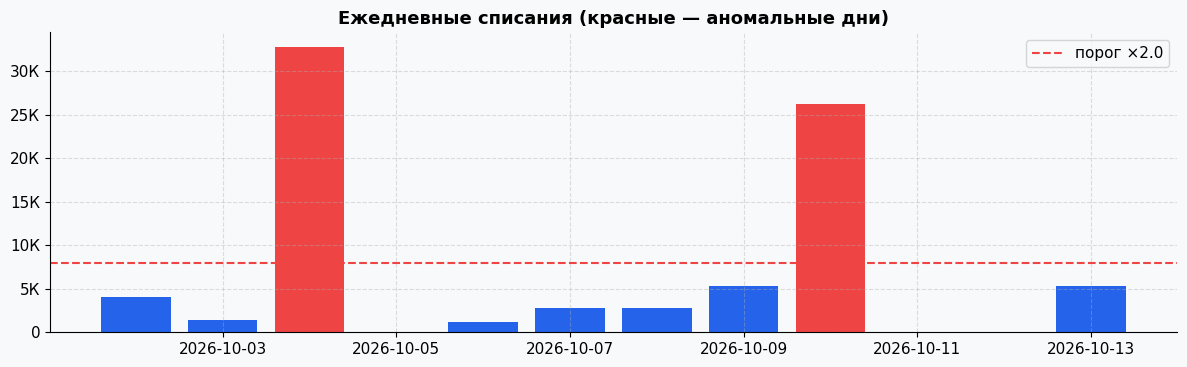

ℹ️ Выгрузка «Списания» сделана на уровне документов (без позиций в товарах). Чтобы видеть, ЧТО именно списывают:
   в Бизнес.Ру откройте «Склад → Списания», зайдите в карточку документа и выгрузите её, либо используйте отчёт «Ведомость по товарам» с типом «Списание».
🧮 Сверка «Бизнес.Ру vs Касса»: дней 14, с расхождением >5%: 4
💸 Позиций проданных >15% ниже медианной цены: 4 — пиковые дни: {Timestamp('2026-10-01 00:00:00'): np.int64(1), Timestamp('2026-10-08 00:00:00'): np.int64(1), Timestamp('2026-10-09 00:00:00'): np.int64(1), Timestamp('2026-10-11 00:00:00'): np.int64(1)}
ℹ️ В файле инвентаризации не нашлись колонки «по учёту / фактически» — обычно они есть в карточке инвентаризации Бизнес.Ру, выгружайте её с деталями по товарам.
👻 НЕОБЪЯСНЁННЫЙ РАСХОД: 28 товаров, 1547 шт ≈ 136 813 ₽ по себестоимости
   Это товар, который ушёл со склада, но его нет ни в чеках, ни в списаниях:
   причины: комплектация букетов (нужен отдельный отчёт!), непробитые продажи, порча без документа, хищение

,Товар,Категория,"Расход, шт","Чеки, шт","Списания, шт","Необъяснённый расход, шт","Потеря, ₽ (себест.)"
335,"Роза микс Э, шт. Размер: 50",Розы,322.0,97.0,0.0,225.0,20638.0
337,"Роза микс Э, шт. Размер: 70",Розы,192.0,39.0,0.0,153.0,17107.0
336,"Роза микс Э, шт. Размер: 60",Розы,480.0,354.0,0.0,126.0,14120.0
90,Георгины,Прочая срезка,168.0,48.0,0.0,120.0,14400.0
340,"Роза микс, шт. Размер: 60",Розы,156.0,38.0,0.0,118.0,10627.0
296,Писташ банч,Зелень и наполнители,105.0,1.0,0.0,104.0,3515.0
223,"Кустовая роза Кения, шт. Размер: 40",Розы,86.0,6.0,0.0,80.0,2560.0
339,"Роза микс, шт. Размер: 50",Розы,114.0,35.0,0.0,79.0,5085.0
440,Хризантема кустовая,Хризантемы,167.0,107.0,0.0,60.0,5082.0
442,Хризантема одноголовая К,Хризантемы,294.0,239.0,0.0,55.0,7700.0


🗑 Документы «Списание» за период: 12, сумма (как в выгрузке) 166 090 ₽; без причины — 12, круглые суммы — 0, после 20:00 — 1


,Дата,Номер,Сумма,Владелец,Причина
8,2026-10-04 19:31:00,199,64 111 ₽,Козлова Светлана,NaN
3,2026-10-10 17:08:00,204,50 178 ₽,Козлова Светлана,NaN
0,2026-10-13 16:02:00,207,10 734 ₽,Козлова Светлана,NaN
4,2026-10-09 09:06:00,203,10 699 ₽,Козлова Светлана,NaN
11,2026-10-02 14:53:00,196,8 129 ₽,Козлова Светлана,NaN



🚨 ИТОГО сигналов к проверке: 20


,Проверка,Объект,Метрика,Комментарий
0,17.2 Пик списаний,04.10.2026,32 816 ₽,Списание в 8.2× выше типичного дня (3 996 ₽) —...
1,17.2 Пик списаний,10.10.2026,26 169 ₽,Списание в 6.5× выше типичного дня (3 996 ₽) —...
2,17.5 Движение↔Касса,07.10.2026,+6.6%,"товар по документу ушёл, денег в кассе нет (ил..."
3,17.5 Движение↔Касса,09.10.2026,-6.4%,"товар по документу ушёл, денег в кассе нет (ил..."
4,17.5 Движение↔Касса,11.10.2026,-7.3%,"товар по документу ушёл, денег в кассе нет (ил..."
5,17.5 Движение↔Касса,14.10.2026,-6.1%,"товар по документу ушёл, денег в кассе нет (ил..."
6,17.6 Дешевые продажи,01.10.2026,1 поз.,много продаж >15% ниже медианы — занижение сум...
7,17.6 Дешевые продажи,08.10.2026,1 поз.,много продаж >15% ниже медианы — занижение сум...
8,17.6 Дешевые продажи,09.10.2026,1 поз.,много продаж >15% ниже медианы — занижение сум...
9,17.9 Необъяснённый расход,"Роза микс Э, шт. Размер: 50",+225 шт / 20 638 ₽,ушёл со склада без чека и без списания — компл...



💸 ОРИЕНТИР ПО ДЕНЬГАМ (по себестоимости):
   • Необъяснённый расход со склада: 136 813 ₽
   • Списания за период:             81 645 ₽
   • Разница «Движение ↔ Касса»:     21 710 ₽
   ⚠️ Это гипотезы для проверки, а не приговор: сначала комплектации и ошибки учёта, потом люди.


In [71]:
alerts = []

# ---- 17.1 Невязки остатков ----
if len(bad):
    for _,r in bad.sort_values('Невязка, шт').iterrows():
        alerts.append({'Проверка':'17.1 Невязка остатков','Объект':r['Товар'],
                       'Метрика':f'{r["Невязка, шт"]:+.0f} шт',
                       'Комментарий':'Расход+приход не сходится с остатком — возможная кража или незадокументированное движение'})

# ---- 17.2 Дневные списания: аномальные дни (robust z-score) ----
wo_daily = docs_f[docs_f['Это_списание']].groupby(docs_f['Дата'].dt.normalize())['Расход (себест.)'].sum()
if len(wo_daily)==0 and W_DOCS is not None:
    wd = W_DOCS.dropna(subset=['Дата'])
    wd = wd[(wd['Дата']>=_dmin)&(wd['Дата']<=_dmax)]
    wo_daily = wd.groupby(wd['Дата'].dt.normalize())['Сумма'].sum()
    if wo_retail:                       # приводим розничные суммы к себестоимости (та же оценка, что и в KPI)
        wo_daily = wo_daily * (total_cost / max(total_rev, 1))
elif len(wo_daily)==0 and W_LINES is not None:
    wl = W_LINES.dropna(subset=['Дата'])
    wl = wl[(wl['Дата']>=_dmin)&(wl['Дата']<=_dmax)]
    wo_daily = wl.groupby(wl['Дата'].dt.normalize())['Сумма'].sum()
    if wo_retail:
        wo_daily = wo_daily * (total_cost / max(total_rev, 1))
print(f'🗑 Источник данных о списаниях: {wo_source}, всего за период: {rub(wo_daily.sum()) if len(wo_daily) else rub(wo_sum)}')
if len(wo_daily) >= 5:
    med = wo_daily.median(); mad = (wo_daily-med).abs().median()
    spike_days = wo_daily[wo_daily > med*WRITEOFF_SPIKE_KOEF + 3*mad*1.4826]
    for d,v in spike_days.items():
        alerts.append({'Проверка':'17.2 Пик списаний','Объект':f'{d:%d.%m.%Y}',
                       'Метрика':rub(v),
                       'Комментарий':f'Списание в {v/med:.1f}× выше типичного дня ({rub(med)}) — проверить акты и камеры'})
    print(f'🗑 Списания: всего {rub(wo_daily.sum())} за {len(wo_daily)} дн., типичный день {rub(med)}, максимум {rub(wo_daily.max())} ({wo_daily.idxmax():%d.%m})')
    fig, ax = plt.subplots(figsize=(12,3.8))
    cols = [PALETTE[3] if v>med*WRITEOFF_SPIKE_KOEF else PALETTE[0] for v in wo_daily]
    ax.bar(wo_daily.index, wo_daily.values, color=cols)
    ax.axhline(med*WRITEOFF_SPIKE_KOEF, ls='--', color=PALETTE[3], label=f'порог ×{WRITEOFF_SPIKE_KOEF}')
    ax.set_title('Ежедневные списания (красные — аномальные дни)'); ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); plt.tight_layout(); plt.show()

# ---- 17.3 Что именно списываем: ходовые позиции не должны «засыхать» массово ----
wo_lines = docs_f[docs_f['Это_списание']].groupby('Товар').agg(Шт=('Расход, шт','sum'), Сумма=('Расход (себест.)','sum'))
if len(wo_lines)==0 and W_LINES is not None:
    wo_lines = W_LINES.groupby('Товар').agg(Шт=('Кол-во','sum'), Сумма=('Сумма','sum'))
elif len(wo_lines)==0 and W_DOCS is not None:
    print('ℹ️ Выгрузка «Списания» сделана на уровне документов (без позиций в товарах). Чтобы видеть, ЧТО именно списывают:')
    print('   в Бизнес.Ру откройте «Склад → Списания», зайдите в карточку документа и выгрузите её, либо используйте отчёт «Ведомость по товарам» с типом «Списание».')
sold_rank = df_s[~df_s['Возврат']].groupby('Товар')['Кол-во'].sum().rank(pct=True)
if len(wo_lines):
    wo_lines['Ранг продаж'] = wo_lines.index.map(sold_rank)
    suspect_wo = wo_lines[(wo_lines['Ранг продаж']>0.7)&(wo_lines['Сумма']>0)].sort_values('Сумма',ascending=False)
    if len(suspect_wo):
        display(suspect_wo.head(10))
        print('↑ Списываются ТОВАРЫ ИЗ ТОП-30% по продажам — классический след «ложной порчи» (#6). Сверьте с актами/фото.')
        for i,(idx,r) in enumerate(suspect_wo.head(5).iterrows()):
            alerts.append({'Проверка':'17.3 Списание ходового','Объект':idx,
                           'Метрика':rub(r['Сумма']),
                           'Комментарий':'ходовая позиция списана «на порчу» — проверить акт и фото'})

# ---- 17.4 Возвраты чеков ----
rets = df_s[df_s['Возврат']].copy()
if len(rets):
    ret_daily = rets.groupby(rets['Дата'].dt.normalize()).size()
    checks_daily = df_s.groupby(df_s['Дата'].dt.normalize())['check_key'].nunique()
    rate = (ret_daily/checks_daily*100).fillna(0)
    late = rets[rets['Час'].notna() & (rets['Час']>=18)]
    print(f'↩️ Возвратов: {len(rets)} позиций ({rate.mean():.1f}% чеков в среднем). Из них после 18:00 — {len(late)} ({len(late)/len(rets)*100:.0f}%)')
    if rate.mean()>RETURN_RATE_ALERT:
        alerts.append({'Проверка':'17.4 Возвраты','Объект':'весь магазин','Метрика':f'{rate.mean():.1f}%',
                       'Комментарий':'высокая доля возвратов — выборка журналов отмен'})
    worst_days = rate.sort_values(ascending=False).head(3)
    for d,v in worst_days.items():
        alerts.append({'Проверка':'17.4 Пик возвратов','Объект':f'{d:%d.%m.%Y}','Метрика':f'{v:.0f}% чеков',
                       'Комментарий':'всплеск возвратов — проверить отмены этого дня (камера + журнал)'})
    fig, ax = plt.subplots(figsize=(12,3.5))
    ax.bar(rate.index, rate.values, color=[PALETTE[3] if v>rate.quantile(.9) else PALETTE[4] for v in rate])
    ax.set_title('Доля чеков с возвратом по дням'); plt.tight_layout(); plt.show()
    # возвраты без «второй жизни»: товар вернули и больше ни разу не продали
    _last_sale_dt = df_s[~df_s['Возврат']].groupby('Товар')['Дата'].max()     # быстро: последняя продажа каждого товара
    no_resale = [t for t, d in zip(rets['Товар'], rets['Дата'])
                 if not (_last_sale_dt.get(t, pd.Timestamp.min) > d)]
    if no_resale:
        print(f'⚠️ После возврата товар так и не продался ни разу: {len(no_resale)} позиций — часть может быть «возвратом на бумаге» (#1).')

# ---- 17.5 Сверка Движение ↔ Касса (если есть кассовый файл) ----
cash_rev_by_day = None
cmp = pd.DataFrame()          # таблица сверки кассы (пустая, если файла кассы нет)
CASH_TRUST_RATIO = 3.0        # если касса больше Бизнес.Ру в X+ раз — файлы не за один период, сверку не делаем
if cash is not None and len(cash):
    it_cols = [c for c in cash.columns if c.lower().startswith('итого')]
    if not it_cols:
        it_cols = [c for c in cash.columns if 'итого' in c.lower() or 'выручка' in c.lower()]
    if it_cols:
        cr = cash.groupby('Дата')[it_cols].sum().sum(axis=1)
        cash_rev_by_day = cr.rename('Касса')
        mv_daily = df_s.groupby(df_s['Дата'].dt.normalize())['Выручка'].sum()
        cmp = pd.DataFrame({'Касса': cash_rev_by_day, 'БизнесРу': mv_daily}).dropna()
        cmp['Разница'] = cmp['БизнесРу'] - cmp['Касса']
        cmp['Разница %'] = np.where(cmp['Касса']>0, cmp['Разница']/cmp['Касса']*100, np.nan)
        if cmp['Касса'].sum() > cmp['БизнесРу'].sum() * CASH_TRUST_RATIO:
            print(f'⚠️ Файл кассы охватывает much большую сумму ({rub(cmp["Касса"].sum())}), чем продажи из Движения за период ({rub(cmp["БизнесРу"].sum())}).')
            print('   Похоже, даты периода (DATE_FROM/DATE_TO) или файл кассы взяты не за одно время — сверка по дням отменена.')
            print('   Проверьте: в настройках период должен совпадать с листом кассы (например, 1–13 октября).')
            cmp = cmp.iloc[0:0]
            cash_rev_by_day = None
        big = cmp[cmp['Разница %'].abs()>CASH_DIFF_PCT]
        print(f'🧮 Сверка «Бизнес.Ру vs Касса»: дней {len(cmp)}, с расхождением >{CASH_DIFF_PCT}%: {len(big)}')
        for d,r in big.head(10).iterrows():
            alerts.append({'Проверка':'17.5 Движение↔Касса','Объект':f'{d:%d.%m.%Y}',
                           'Метрика':f'{r["Разница %"]:+.1f}%',
                           'Комментарий':'товар по документу ушёл, денег в кассе нет (или наоборот) — непробитая продажа (#2)'})

# ---- 17.6 Цены по дням (кто продаёт дешевле прайса) ----
price_ref = df_s.groupby('Товар')['Цена продажи'].median()
tmp = df_s[~df_s['Возврат']].copy()
_ref = tmp['Товар'].map(price_ref)
tmp['отклонение'] = np.where(_ref > 0, (tmp['Цена продажи'] - _ref) / _ref.where(_ref > 0) * 100, np.nan)
disc_days = tmp[tmp['отклонение']<-PRICE_DISCOUNT_PCT].groupby(tmp['Дата'].dt.normalize()).size()
if len(disc_days):
    print(f'💸 Позиций проданных >{PRICE_DISCOUNT_PCT}% ниже медианной цены: {int((tmp["отклонение"]<-PRICE_DISCOUNT_PCT).sum())} — пиковые дни: {dict(disc_days.sort_values(ascending=False).head(5).astype(int))}')
    for d,c in disc_days.sort_values(ascending=False).head(3).items():
        alerts.append({'Проверка':'17.6 Дешевые продажи','Объект':f'{d:%d.%m.%Y}','Метрика':f'{int(c)} поз.',
                       'Комментарий':f'много продаж >{PRICE_DISCOUNT_PCT}% ниже медианы — занижение суммы (#3)?'})

# ---- 17.7 Пересортица: плюс одного = минус другого в один день ----
mv_by_day_item = docs_f.groupby([docs_f['Дата'].dt.normalize(),'Товар'])['Расход, шт'].sum()
cross = []
for d, grp in mv_by_day_item.groupby(level=0):
    neg = grp[grp<=-5]; pos = grp[grp>=5]
    if len(neg) and len(pos):
        cross.append({'Дата': d, 'Минус': ', '.join(neg.index.get_level_values(1)[:3]),
                      'Плюс': ', '.join(pos.index.get_level_values(1)[:3])})
if cross:
    print(f'🔄 Дней с одновременным «плюсом» и «минусом» крупных партий (возможная пересортица #9): {len(cross)}')

# ---- 17.8 Инвентаризации: реальные недостачи (если есть файл) ----
inv = extra.get('Инвентаризации')
if inv is not None:
    pcol = next((c for c in inv.columns if any(w in norm_name(c) for w in ['наименован','товар'])), None)
    dcol = next((c for c in inv.columns if any(w in norm_name(c) for w in ['учет','учёт','книжн','расч']) ), None)
    fcol = next((c for c in inv.columns if 'факт' in norm_name(c) and c != dcol), None)
    if pcol and dcol and fcol:
        t = pd.DataFrame({'Товар': inv[pcol].astype(str).str.strip(),
                          'По учёту': to_num(inv[dcol]), 'Факт': to_num(inv[fcol])})
        t['Недостача, шт'] = t['Факт'] - t['По учёту']
        short = t[t['Недостача, шт'] < 0].groupby('Товар')['Недостача, шт'].sum().sort_values()
        if len(short):
            uc2 = unit_cost_by(df_s[~df_s['Возврат']], 'Товар')
            short_df = short.to_frame('Недостача, шт')
            short_df['₽ по себестоимости'] = (-short_df['Недостача, шт'] * short_df.index.map(uc2)).fillna(0)
            print(f'📉 По инвентаризациям: {len(short_df)} позиций с недостачей на {rub(short_df["₽ по себестоимости"].sum())}')
            display(short_df.head(10))
            for idx, r in short_df.head(5).iterrows():
                alerts.append({'Проверка':'17.8 Недостача по инвентаризации','Объект':idx,
                               'Метрика':f'{r["Недостача, шт"]:+.0f} шт',
                               'Комментарий':'факт меньше учёта без документов — прямое следствие #2/#11'})
    else:
        print('ℹ️ В файле инвентаризации не нашлись колонки «по учёту / фактически» — обычно они есть в карточке инвентаризации Бизнес.Ру, выгружайте её с деталями по товарам.')

# ---- 17.9 «Невидимый расход»: всё ли ушедшее со склада объяснено документами? ----
# Берём товары, по которым в периоде были движения, и сверяем:
#   расход по Движению  vs  чеки + списания, которые мы видим в данных.
mv_items = set(docs_f['key'])
st_f2 = stock[stock['key'].isin(mv_items)].copy()
sold_by_key = df_s[~df_s['Возврат']].groupby('key')['Кол-во'].sum()
ret_by_key  = df_s[df_s['Возврат']].groupby('key')['Кол-во'].sum().abs()
wo_by_key   = docs_f[docs_f['Это_списание']].groupby('key')['Расход, шт'].sum()
if wo_by_key.sum() == 0 and W_LINES is not None:
    _wl = W_LINES.copy(); _wl['key'] = _wl['Товар'].map(norm_name)
    wo_by_key = _wl.groupby('key')['Кол-во'].sum().abs()
st_f2['Чеки, шт']      = st_f2['key'].map(sold_by_key).fillna(0)
st_f2['Возвраты, шт']  = st_f2['key'].map(ret_by_key).fillna(0)
st_f2['Списания, шт']  = st_f2['key'].map(wo_by_key).fillna(0)
st_f2['Объяснено, шт'] = st_f2['Чеки, шт'] - st_f2['Возвраты, шт'] + st_f2['Списания, шт']
st_f2['Необъяснённый расход, шт'] = (st_f2['Расход, шт'] - st_f2['Объяснено, шт']).round(1)
unexp = st_f2[st_f2['Необъяснённый расход, шт'] >= 5].sort_values('Необъяснённый расход, шт', ascending=False)
uc_all = unit_cost_by(df_s[~df_s['Возврат']], 'key')
unexp['Потеря, ₽ (себест.)'] = (unexp['Необъяснённый расход, шт'] * unexp['key'].map(uc_all).fillna(0)).round(0)
loss_total = float(unexp['Потеря, ₽ (себест.)'].sum())
print(f'👻 НЕОБЪЯСНЁННЫЙ РАСХОД: {len(unexp)} товаров, {int(unexp["Необъяснённый расход, шт"].sum())} шт ≈ {rub(loss_total)} по себестоимости')
print('   Это товар, который ушёл со склада, но его нет ни в чеках, ни в списаниях:')
print('   причины: комплектация букетов (нужен отдельный отчёт!), непробитые продажи, порча без документа, хищение.')
if len(unexp):
    display(unexp[['Товар','Категория','Расход, шт','Чеки, шт','Списания, шт','Необъяснённый расход, шт','Потеря, ₽ (себест.)']].head(15))
    for _, r in unexp.head(8).iterrows():
        alerts.append({'Проверка':'17.9 Необъяснённый расход','Объект':r['Товар'],
                       'Метрика':f'{r["Необъяснённый расход, шт"]:+.0f} шт / {rub(r["Потеря, ₽ (себест.)"])}',
                       'Комментарий':'ушёл со склада без чека и без списания — комплектация? непробитие (#2)? кража (#11)?'})

# ---- 17.10 Крупные списания без причины и круглые суммы (из файла «Списания») ----
if W_DOCS is not None:
    _wd = W_DOCS.dropna(subset=['Дата'])
    _wd = _wd[(_wd['Дата']>=_dmin)&(_wd['Дата']<=_dmax)]
    if len(_wd):
        no_rsn = _wd[_wd['Причина'].isna() | _wd['Причина'].astype(str).str.strip().isin(['','nan','.'])]
        rnd    = _wd[_wd['Сумма'].fillna(0) % 1000 == 0]
        late   = _wd[_wd['Час'] >= 20]
        print(f'🗑 Документы «Списание» за период: {len(_wd)}, сумма (как в выгрузке) {rub(_wd["Сумма"].sum())}; '
              f'без причины — {len(no_rsn)}, круглые суммы — {len(rnd)}, после 20:00 — {len(late)}')
        if len(_wd) and (_wd['Сумма'].median() or 0) >= 100_000:
            print('❗ Медианная сумма списания ≥ 100 тыс. ₽ — похоже, это суммы ЗАКУПОК, а не порчи.')
            print('   Проверьте, тот ли файл лежит в data/: нужен «Списания» (Склад), а не «Поступления» (Закупки).')
        big_wo = _wd.sort_values('Сумма', ascending=False).head(5)
        display(big_wo[['Дата','Номер','Сумма','Владелец','Причина']].assign(
            Сумма=big_wo['Сумма'].map(lambda v: rub(v))))
        for _, r in big_wo.head(3).iterrows():
            alerts.append({'Проверка':'17.10 Крупное списание','Объект':f'№{r["Номер"]} от {r["Дата"]:%d.%m.%Y}',
                           'Метрика':rub(r['Сумма']),
                           'Комментарий':'крупная сумма%s — запросите акт и фото; проверьте, кто создал документ (%s)' % (' и нет причины' if str(r['Причина']) in ('nan','','.') else '', r['Владелец'])})

# ---- Итоговая таблица алертов ----
alert_df = pd.DataFrame(alerts)
print('\n' + '='*60)
print(f'🚨 ИТОГО сигналов к проверке: {len(alert_df)}')
print('='*60)
if len(alert_df): display(alert_df)
else: print('✅ Явных аномалий не найдено. Это хорошо — но не отменяет регулярных слепых инвентаризаций.')

print('\n💸 ОРИЕНТИР ПО ДЕНЬГАМ (по себестоимости):')
print(f'   • Необъяснённый расход со склада: {rub(loss_total)}')
_wo_est = float(wo_daily.sum()) if len(wo_daily) else wo_sum
print(f'   • Списания за период:             {rub(_wo_est)}')
print(f'   • Разница «Движение ↔ Касса»:     {rub(float(cmp["Разница"].abs().sum())) if cash_rev_by_day is not None and len(cmp) else "нет файла кассы"}')
print('   ⚠️ Это гипотезы для проверки, а не приговор: сначала комплектации и ошибки учёта, потом люди.')

<a id='шаг18'></a>
# 18. 👤 Карточка сотрудника и риск-скоринг (+ машинное обучение)

**Откуда берутся «сотрудники»?** В стандартном «Движении товаров» имени кассира нет. Поэтому блокнот использует два источника имён:
1. колонка **«Владелец»** из документов Бизнес.Ру (Поступления/Списания — тот, кто создал документ);
2. **ваш кассовый файл контроля** (`Курская_Контроль_*.xlsx`), если в нём есть колонка с фамилией продавца.
Если имён нет — анализ сотрудников пропускается, но остальные проверки работают.

**Как считается риск-балл:** по каждому человеку считаем долю списаний, возвратов, крупных скидок, продаж ниже себестоимости и «ночных» операций; сравниваем с *медианой коллег* (в N раз хуже = флаг); флаги складываются с весами. Плюс **IsolationForest** — алгоритм, который сам находит «странные смены» по набору признаков (это классический датасет *fraud detection*: аномалии ищем не по одному признаку, а по комбинации).

> ⚖️ Балл — повод задать вопросы и посмотреть камеры, а не основание для увольнения. У каждого флага есть «невинное объяснение» — оно печатается рядом.

👥 Источники имён: касса — есть, владелец списаний по дням — 2 шт (Администратор, Козлова Светлана), все владельцы документов — ['Администратор', 'Козлова Светлана', 'Фамилия Имя']


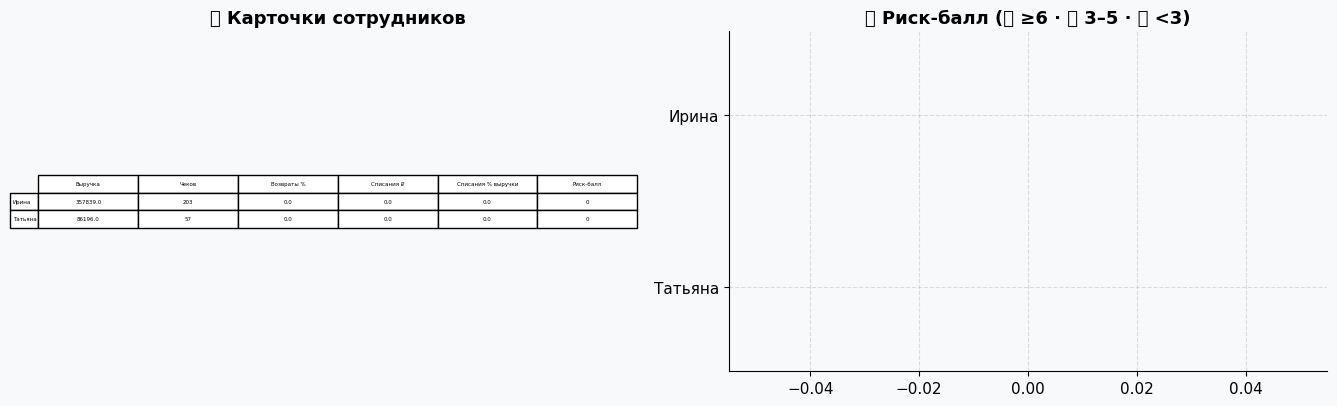

Расшифровка флагов (с «невинными» объяснениями):
  • Ирина — флагов нет ✅
  • Татьяна — флагов нет ✅
🤖 IsolationForest отметил аномальных смен: 1 из 14 (ожидаемо ~5%)


,Выручка,Чеков,Списания,Возвраты,Ср.цена отклонение,Аномалия,score
Дата,,,,,,,
2026-10-15,7744.14,3,0.0,0.0,4.04,True,0.64


→ Смотрите, ЧЕМ странна смена: всплеск списаний при нормальных продажах, много возвратов, «нулевые» продажи и т.п.


In [72]:
# ---------- 18.0 Кто есть кто: собираем «имена» из доступных источников ----------
emp_lines = pd.Series(index=df_s.index, dtype=object)

# 1) Списания: «Владелец» документа — кто оформил списание (обычно старший смены)
wo_owner = {}
W_SRC = W_LINES if W_LINES is not None else W_DOCS
if W_SRC is not None and 'Владелец' in W_SRC.columns:
    for d, o in zip(W_SRC['Дата'], W_SRC['Владелец']):
        if pd.notna(d) and str(o).strip() not in ('','Не указан','nan'):
            wo_owner.setdefault(pd.Timestamp(d).normalize(), set()).add(str(o).strip())

# 2) Кассовый контроль: колонка «Смена» / «Кассир» / «Сотрудник» — кто был на кассе в этот день
shift_emp = None
if cash is not None and len(cash) and 'Дата' in cash.columns:
    ecol = next((c for c in cash.columns if any(w in c.lower() for w in
              ['сотрудник','кассир','фамилия','владелец','продац','смена'])), None)
    if ecol:
        shift_emp = cash.groupby('Дата')[ecol].agg(
            lambda s: ', '.join(sorted({str(x).strip() for x in s.dropna()})))

df_s['Сотрудник'] = 'Не указан'
day_keys = df_s['Дата'].dt.normalize()
if shift_emp is not None:
    df_s['Сотрудник'] = day_keys.map(shift_emp).fillna('Не указан')
_doc_owners = sorted({o for v in wo_owner.values() for o in v})
print(f'👥 Источники имён: касса — {"есть" if shift_emp is not None else "нет"}, '
      f'владелец списаний по дням — {len(_doc_owners)} шт ({", ".join(_doc_owners) if _doc_owners else "нет"}), '
      f'все владельцы документов — {sorted(owners_all)}')

named = df_s[df_s['Сотрудник']!='Не указан']
if len(named)==0:
    print('ℹ️ Имён сотрудников нет ни в кассовом файле, ни в документах — раздел 18.1 пропускается.')
    emp = None
else:
    # ---------- 18.1 Свод по людям ----------
    sl = named[~named['Возврат']].copy()
    rt = named[named['Возврат']]
    g = sl.groupby('Сотрудник')
    emp = pd.DataFrame({'Выручка': g['Выручка'].sum(), 'Смен(дней)': g['Дата'].apply(lambda s: s.dt.normalize().nunique()),
                        'Чеков': g['check_key'].nunique()})
    emp['Выручка/смену'] = emp['Выручка']/emp['Смен(дней)'].replace(0,np.nan)
    emp['Средний чек'] = emp['Выручка']/emp['Чеков'].replace(0,np.nan)
    price_ref2 = sl.groupby('Товар')['Цена продажи'].median()
    _r2 = sl['Товар'].map(price_ref2)
    sl['dev'] = np.where(_r2 > 0, (_r2 - sl['Цена продажи']) / _r2.where(_r2 > 0) * 100, np.nan)
    emp['Цены ниже медианы'] = (-sl['dev'].clip(lower=0)).groupby(sl['Сотрудник']).mean()/100
    emp['Возвраты, доля'] = rt.groupby('Сотрудник').size().reindex(emp.index).fillna(0)/emp['Чеков']
    off_mask = sl['Час'].notna() & ((sl['Час']<WORK_START)|(sl['Час']>=WORK_END))
    emp['Вне часов'] = off_mask.groupby(sl['Сотрудник']).mean().reindex(emp.index).fillna(0)
    def wo_for_person(person_days, name_tokens):
        # если списания привязаны к владельцу — считаем его личные; иначе — все за его смены
        if W_SRC is not None and 'Владелец' in W_SRC.columns and 'Сумма' in W_SRC.columns:
            m = W_SRC['Владелец'].astype(str).apply(lambda v: any(t in v for t in name_tokens))
            per = W_SRC[m]
            per = per[(per['Дата']>=_dmin)&(per['Дата']<=_dmax)]
            return float(per['Сумма'].fillna(0).sum())
        tot = 0.0
        for d in person_days:
            tot += float(wo_daily.get(d, 0))
        return tot
    emp['Списания ₽'] = [wo_for_person(g2['Дата'].dt.normalize().unique(), [t for t in str(idx).split() if len(t)>2])
                         for idx, g2 in sl.groupby('Сотрудник')]
    emp['Списания % выручки'] = emp['Списания ₽']/emp['Выручка'].replace(0,np.nan)
    below_cost = (sl['Себестоимость']-sl['Выручка']).clip(lower=0)
    emp['Ниже себестоимости'] = below_cost.groupby(sl['Сотрудник']).sum()/emp['Выручка']

    WEIGHTS = {'Списания % выручки':2,'Возвраты, доля':2,'Цены ниже медианы':1,'Вне часов':1,'Ниже себестоимости':2}
    LABEL = {'Списания % выручки':'Списания относительно выручки','Возвраты, доля':'Доля возвратов',
             'Цены ниже медианы':'Продажи дешевле обычной цены','Вне часов':'Операции вне графика',
             'Ниже себестоимости':'Продажи ниже себестоимости'}
    INNOCENT = {'Списания % выручки':'отвечает за приёмку/холодильник, «тяжёлые» смены',
                'Возвраты, доля':'принимает претензии клиентов на кассе',
                'Цены ниже медианы':'продаёт акции/увядающее, работает с постоянниками',
                'Вне часов':'закрывает смену, оформляет документы позже',
                'Ниже себестоимости':'уценивает вот-вот завядшее'}
    ratio = pd.DataFrame(index=emp.index)
    for k in WEIGHTS:
        x = emp[k].astype(float)
        base = max(x.median(), 0.3*x.mean(), 1e-9)
        ratio[k] = x/base
    flags = pd.DataFrame({k:(ratio[k]>=FLAG_RATIO)&(emp[k]>emp[k].median()) for k in WEIGHTS})
    score = (flags*pd.Series(WEIGHTS)).sum(axis=1)
    emp['Риск-балл'] = score
    order = score.sort_values(ascending=False).index

    fig, axes = plt.subplots(1,2, figsize=(14,4.2))
    show_cols = ['Выручка','Чеков','Возвраты, доля','Списания ₽','Списания % выручки','Риск-балл']
    disp = emp.loc[order, show_cols].copy()
    for c in ['Возвраты, доля','Списания % выручки']:
        disp[c] = (disp[c]*100).round(1)
    disp = disp.rename(columns={'Возвраты, доля':'Возвраты %','Списания % выручки':'Списания % выручки'})
    axes[0].table(disp.round(0).astype(str).values, colLabels=disp.columns, rowLabels=list(disp.index), loc='center', cellLoc='center')
    axes[0].axis('off'); axes[0].set_title('📋 Карточки сотрудников')
    cols = [PALETTE[3] if v>=6 else PALETTE[2] if v>=3 else PALETTE[1] for v in score.loc[order]]
    axes[1].barh(list(order)[::-1], score.loc[order].values[::-1], color=cols[::-1])
    axes[1].set_title('🌡️ Риск-балл (🟥 ≥6 · 🟧 3–5 · 🟩 <3)')
    plt.tight_layout(); plt.show()

    print('Расшифровка флагов (с «невинными» объяснениями):')
    for e in order:
        hit = [k for k in flags.columns if flags.loc[e,k]]
        if hit:
            print(f'  • {e} — балл {score[e]:.0f}: ' + '; '.join(f'{LABEL[k]} ×{ratio.loc[e,k]:.1f} (возможно: {INNOCENT[k]})' for k in hit))
        else:
            print(f'  • {e} — флагов нет ✅')

# ---------- 18.2 Isolation Forest: алгоритм сам ищет «странные» смены ----------
try:
    from sklearn.ensemble import IsolationForest
    base = named if len(named) else df_s
    sl2 = base[~base['Возврат']].copy()
    day = sl2['Дата'].dt.normalize()
    ed = sl2.groupby(day).agg(Выручка=('Выручка','sum'), Чеков=('check_key','nunique'))
    ed['Списания'] = wo_daily.reindex(ed.index).fillna(0) if len(wo_daily) else 0
    ret_cnt = df_s[df_s['Возврат']].groupby(df_s['Дата'].dt.normalize()).size()
    ed['Возвраты'] = ret_cnt.reindex(ed.index).fillna(0)
    ed['Ср.цена отклонение'] = tmp.set_index(tmp['Дата'].dt.normalize()).groupby(level=0)['отклонение'].mean().reindex(ed.index).abs().fillna(0)
    X = ed[['Чеков','Выручка','Списания','Возвраты','Ср.цена отклонение']].replace([np.inf,-np.inf],0).fillna(0)
    iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=0).fit(X)
    ed['Аномалия'] = iso.predict(X)==-1
    ed['score'] = -iso.score_samples(X)
    anom = ed[ed['Аномалия']].sort_values('score',ascending=False)
    print(f'🤖 IsolationForest отметил аномальных смен: {len(anom)} из {len(ed)} (ожидаемо ~5%)')
    if len(anom):
        display(anom.round(2).head(10))
        print('→ Смотрите, ЧЕМ странна смена: всплеск списаний при нормальных продажах, много возвратов, «нулевые» продажи и т.п.')
except ImportError:
    print('ℹ️ scikit-learn не установлен — ML-раздел пропущен (pip install scikit-learn).')

<a id='шаг19'></a>
# 19. 📋 Итоговое резюме — что сказать владельцу

Автогенерируемый текст «на один экран»: цифры, топ-товары, потери, что заказать, что проверить. Скопируйте его в мессенджер/почту — и отчёт готов.

In [73]:
top3 = abc_rev.head(3)['Товар'].tolist()
share_top = abc_rev[abc_rev['Класс']=='A']
worst_wo_day = wo_daily.idxmax() if len(wo_daily) else None
worst_str = f'{worst_wo_day:%d.%m} ({rub(wo_daily.max())})' if len(wo_daily) else 'нет'
emp_line = ''
if 'emp' in dir() and emp is not None and len(emp):
    riskiest = emp['Риск-балл'].sort_values(ascending=False)
    if len(riskiest) and riskiest.iloc[0] >= 3:
        emp_line = f'\n• Максимальный риск-балл у: {riskiest.index[0]} ({riskiest.iloc[0]:.0f}) — посмотреть карточку в разделе 18.'
rfm_line = ''
if 'rfm' in dir() and rfm is not None:
    _ch = rfm[rfm['Сегмент']=='🚨 Уходят (были лучшими!)']
    if len(_ch):
        rfm_line = f'\n• 📞 Вернуть звонком: {len(_ch)} «уходящих» лучших клиентов (принесли {rub(_ch["Потрачено"].sum())}) — раздел 13.1.'
print(f'''
🧾 РЕЗЮМЕ ЗА ПЕРИОД {_dmin:%d.%m} — {_dmax:%d.%m}
──────────────────────────────────────────────
• Выручка {rub(total_rev)}, валовая маржа {rub(total_margin)} ({pct(margin_pct)}; цель {MARGIN_TARGET}%).
• Чеков {num_fmt(n_checks)}, средний чек {rub(avg_check)}, в чеке в среднем {items_per_chk:.1f} позиции.
• Класс A: {len(share_top)} товаров дают 80% выручки. Топ-3: {", ".join(top3)}.
• Списания: {rub(wo_sum)} ({wo_sum/total_cost*100 if total_cost else 0:.1f}% от себестоимости продаж). Самый крупный день списаний — {worst_str}.
• Залежалый товар: {len(dead)} позиций на {rub(dead["Остаток, ₽"].sum()) if len(dead) else "0 ₽"}.
• К заказу на {COVER_DAYS} дней: {len(buy)} позиций (~{rub(buy["Сумма закупки, ₽"].sum())}).
• Сигналов аудит-детектора: {len(alert_df)}. Необъяснённый расход со склада: {rub(loss_total)} (см. раздел 17б «Где утечка»).{emp_line}{rfm_line}
──────────────────────────────────────────────
''')
print('✅ Анализ завершён. Ниже — выгрузка всех таблиц в Excel.')


🧾 РЕЗЮМЕ ЗА ПЕРИОД 01.10 — 15.10
──────────────────────────────────────────────
• Выручка 444 035 ₽, валовая маржа 225 760 ₽ (50.8%; цель 40%).
• Чеков 260, средний чек 1 708 ₽, в чеке в среднем 2.1 позиции.
• Класс A: 18 товаров дают 80% выручки. Топ-3: Роза микс Э, шт. Размер: 60, Хризантема одноголовая К, Кустовая роза Кения, шт. Размер: 60.
• Списания: 1 287 133 ₽ (589.7% от себестоимости продаж). Самый крупный день списаний — 04.10 (32 816 ₽).
• Залежалый товар: 160 позиций на 182 335 ₽.
• К заказу на 4 дней: 16 позиций (~17 650 ₽).
• Сигналов аудит-детектора: 20. Необъяснённый расход со склада: 136 813 ₽ (см. раздел 17б «Где утечка»).
──────────────────────────────────────────────

✅ Анализ завершён. Ниже — выгрузка всех таблиц в Excel.


<a id='утечка'></a>
## 17б. 🎯 ГДЕ УТЕЧКА — главный вывод аудита (три слоя)

Блокнот переводит все проверки в деньги и раскладывает потери по трём «дырам»:

| Слой | Что это | Где искать причину |
|---|---|---|
| **1. Списания документированные** | Официально «испорчено» | Реальная порча ИЛИ ложное списание (схема #6) |
| **2. Необъяснённый расход** | Товар ушёл со склада, но нет ни чека, ни списания | Комплектация букетов без отчёта, непробитие (#2), порча без документа, хищение (#11) |
| **3. Расхождение Движение ↔ Касса** | Товар учтён, денег нет | Непробитые продажи, «минусовки» (#1, #2) |

**Как читать результат:**
- Сначала исключите **бытовые** причины слоя 2: сборка букетов/упаковка причины: сборка букетов/упаковка (в Бизнес.Ру нужен отчёт «Комплектация»), возвраты поставщику, перемещения между складами.
- Всё, что осталось после объяснений, — реальный кандидат на хищение.
- **Ориентир рынка:** нормальные потери цветочной розницы — списания 5–10% от себестоимости продаж. Если необъяснённый расход сопоставим со списаниями или больше — учёта фактически нет, и это первая проблема номер один (дороже любого маркетинга).

In [74]:
# ═══════════════════════════════════════════════════════════════
# 17б. ГДЕ УТЕЧКА — собираем все находки в одну денежную картину
# ═══════════════════════════════════════════════════════════════
print('='*60)
print('🎯 ГДЕ УТЕЧКА: ТРИ СЛОЯ ПОТЕРЬ ЗА ПЕРИОД')
print('='*60)

leaks = pd.DataFrame([
    {'Слой': '1. Списания (официальная порча)',
     'Сумма, ₽ (себест.)': round(float(wo_daily.sum()) if len(wo_daily) else wo_sum, 0),
     'Доля от себест. продаж %': round((float(wo_daily.sum()) if len(wo_daily) else wo_sum)/total_cost*100, 1) if total_cost else np.nan,
     'Что делать': 'Сверить акты с фото; смотреть пики в конце смены/месяца и автора документа'},
    {'Слой': '2. Необъяснённый расход со склада',
     'Сумма, ₽ (себест.)': round(loss_total, 0),
     'Доля от себест. продаж %': round(loss_total/total_cost*100, 1) if total_cost else np.nan,
     'Что делать': 'Найти документы-объяснения (комплектация, перемещения, возвраты поставщику). Остаток — слепая инвентаризация топ-20 и камеры'},
    {'Слой': '3. Расхождение Движение ↔ Касса',
     'Сумма, ₽ (себест.)': round(float(cmp['Разница'].sum()), 0) if cash_rev_by_day is not None and len(cmp) else 0,
     'Доля от себест. продаж %': np.nan,
     'Что делать': 'По дням с минусом в кассе — журнал смен ОФД и видео этого дня'},
])
display(leaks)

_big = leaks.loc[leaks['Сумма, ₽ (себест.)'].abs().idxmax()]
_big_txt = f'{_big["Сумма, ₽ (себест.)"]:,.0f}'.replace(',', ' ')
print(f'➡️ Самый большой слой потерь: «{_big["Слой"]}» — {_big_txt} ₽')
if cash_rev_by_day is None:
    print('   (слой 3 = 0 ₽, потому что сверка кассы отменена или файла кассы нет — см. раздел 17.5)')
print(f'   План действий: {_big["Что делать"]}')
print()
print('💡 Памятка владельцу:')
print('   • Слои 1+2+3 — это ГИПОТЕЗЫ, а не приговор людям. Порядок проверки: документы → процессы → только потом сотрудники.')
print('   • Сравните «необъяснённый расход» с итогом СЛЕПОЙ инвентаризации топ-20 товаров: если недостача совпадает — это точно потери, а не учёт.')
print('   • Каждый месяц повторяйте запуск: динамика слоёв важнее абсолютных цифр (утечка лечится процессами, а разовой проверкой).')

🎯 ГДЕ УТЕЧКА: ТРИ СЛОЯ ПОТЕРЬ ЗА ПЕРИОД


,Слой,"Сумма, ₽ (себест.)",Доля от себест. продаж %,Что делать
0,1. Списания (официальная порча),81645.0,37.4,Сверить акты с фото; смотреть пики в конце сме...
1,2. Необъяснённый расход со склада,136813.0,62.7,"Найти документы-объяснения (комплектация, пере..."
2,3. Расхождение Движение ↔ Касса,-365.0,NaN,По дням с минусом в кассе — журнал смен ОФД и ...


➡️ Самый большой слой потерь: «2. Необъяснённый расход со склада» — 136 813 ₽
   План действий: Найти документы-объяснения (комплектация, перемещения, возвраты поставщику). Остаток — слепая инвентаризация топ-20 и камеры

💡 Памятка владельцу:
   • Слои 1+2+3 — это ГИПОТЕЗЫ, а не приговор людям. Порядок проверки: документы → процессы → только потом сотрудники.
   • Сравните «необъяснённый расход» с итогом СЛЕПОЙ инвентаризации топ-20 товаров: если недостача совпадает — это точно потери, а не учёт.
   • Каждый месяц повторяйте запуск: динамика слоёв важнее абсолютных цифр (утечка лечится процессами, а разовой проверкой).


<a id='шаг20'></a>
# 20. 💾 Выгрузка всех таблиц в один Excel

Один файл `output/Отчет_розница_цветы.xlsx`: KPI, динамика, ABC, категории, маржа, связки, остатки, залёжки, план закупки, списания, алерты, прогноз и сами позиции чеков. Его можно отдать бухгалтерии или открыть на телефоне.

In [75]:
if not EXPORT_XLSX:
    print('Выгрузка отключена (EXPORT_XLSX=False).')
else:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out = os.path.join(OUTPUT_DIR, 'Отчет_розница_цветы.xlsx')
    sheets = {
        'KPI': pd.DataFrame([{'показатель':k,'значение':v} for k,v in kpis]),
        'Динамика_день': daily,
        'ABC_выручка': abc_rev, 'ABC_маржа': abc_marg,
        'Категории': cat,
        'Товары_маржа': pm.sort_values('Выручка',ascending=False),
        'MarketBasket': mb if len(mb) else pd.DataFrame(),
        'Остатки': stock, 'Залежалый': dead, 'План_закупки': buy,
        'Списания_дни': wo_daily.rename('Сумма').reset_index() if len(wo_daily) else pd.DataFrame(),
        'Алерты': alert_df,
        'Потери_невязки': bad[['Товар','Нач. остаток','Приход, шт','Расход, шт','Инвентаризация, шт','Кон. остаток','Невязка, шт']] if len(bad) else pd.DataFrame(),
        'Потери_необъясн': unexp[['Товар','Категория','Расход, шт','Чеки, шт','Списания, шт','Необъяснённый расход, шт','Потеря, ₽ (себест.)']] if len(unexp) else pd.DataFrame(),
        'Сверка_касса': cmp.reset_index() if cash_rev_by_day is not None and 'cmp' in dir() else pd.DataFrame(),
        'Прогноз': fc.rename('Прогноз').reset_index().rename(columns={'index':'Дата'}),
        'Чеки_позиции': df_s,
        'RFM_клиенты': rfm.reset_index().rename(columns={'Клиент':'Клиент'}) if 'rfm' in dir() and rfm is not None else pd.DataFrame(),
        'Сезонность': season_tbl if 'season_tbl' in dir() and len(season_tbl) else pd.DataFrame(),
    }
    with pd.ExcelWriter(out, engine='openpyxl') as xw:
        for name, d in sheets.items():
            (d if isinstance(d,pd.DataFrame) else pd.DataFrame()).to_excel(xw, sheet_name=name[:31], index=False)
    print(f'💾 Сохранено: {out}')

💾 Сохранено: output\Отчет_розница_цветы.xlsx


<a id='шаг21'></a>
# 21. 🚀 Куда развивать: Data Science, продуктовая аналитика и BI

Вы уже сделали главное — поставили данные на поток. Вот дорожная карта, что дальше и **какие именно знания Data Science где применяются**:

### Уровень 1. BI-дашборд вместо блокнота (1–2 недели)
- **Инструменты:** Yandex DataLens (бесплатно), Apache Superset, Power BI. Google Sheets + `БУИЗИНС.РУ` выгружает CSV по расписанию? Ещё проще.
- **Что показать владельцу на одном экране:** KPI дня (выручка/чеки/средний чек/маржа), график «план/факт», TOP-10 ABC, списания по дням с порогом, «красные» алерты.
- **Приёмы BI:** сквозные метрики (определите ОДИН раз, что такое «выручка» — и все отделы считают одинаково), декомпозиция метрик (выручка = трафик × конверсия × средний чек), когортные срезы, drill-down от месяца к чеку.

### Уровень 2. Продуктовая аналитика вашего магазина (магазин = продукт)
- **Воронка:** увидели витрину → зашли → собрали букет → купили → вернулись. Точки сбора: вывеска/трафик (счетчик на двери), онлайн-заказы (сайт/Авито/2ГИС — события «просмотр карточки», «оформил»), программа лояльности (возвраты).
- **Когорты и retention (LTV):** по карте клиента/телефону считаем, какая доля покупателей вернулась в 30/60/90 дней, какой «средний клиент» приносит за год. Это меняет решение «давать ли скидку 10%»: скидка оправдана, если поднимает LTV.
- **A/B-тесты:** два варианта витрины/скрипта допродажи («к розам предлагаем эвкалипт или открытку?»), два уровня доставки. Метрика — средний чек/конверсия; проверяем статистической значимостью (t-тест, χ²).
- **North Star Metric:** например «маржа с повторных покупок за месяц» — всё в команде смотрит на неё.

### Уровень 3. Классический Data Science на ваших же данных
- **Прогноз спроса** (заменим медиану дня недели): Prophet / LightGBM с фичами «день недели, праздник, погода (API Яндекс.Погода), цена, прошлые продажи». Результат — точнее закупка → меньше «засохло» → выше маржа. Оценка — backtest, как в разделе 16.
- **Классификация свежести/потерь:** модель предсказывает вероятность списания позиции по возрасту среза, температуре, поставщику — предупреждает заранее.
- **Кластеризация клиентов (RFM + k-means):** «свадебные», «еженедельные офисные», «подарочные редкие» — под каждый кластер своя акция и свой канал.
- **Computer Vision:** распознавание букета по фото для мгновенного оформления заказа и оценки себестоимости сборки (сверка «норматив букета vs факт»).
- **Ансамбли аномалий** (уже начали: IsolationForest) → добавить скоринг по правилам + контрольные карты Шухарта (SPC) на ежедневные списания/возвраты: сигнал, когда процесс «выходит за контрольные пределы».

### Уровень 4. Данные «под ключ» (инженерия)
- Вместо ручных выгрузков: **REST API Бизнес.Ру** (в настройках есть токены доступа) → скрипт-загрузчик (cron) → база PostgreSQL → DataLens читает из базы. Обновление дашборда — каждые 15 минут, без вас.
- Версия для git: названия файлов фиксируем, данные не коммитим (см. `.gitignore`).

### Мини-словарь для общения с данными
| Термин | Простыми словами |
|---|---|
| Метрика | Число, по которому судим об успехе (выручка, средний чек) |
| KPI | Метрика с целью («маржа ≥ 40%») |
| Конверсия | Доля сделавших целевое действие (зашли → купили) |
| Retention | Доля вернувшихся клиентов через N дней |
| LTV | Сколько денег принесёт клиент за всё время |
| ABC/XYZ | «кто кормит» / «насколько стабильно» |
| Cohort | Группа клиентов, объединённых датой первой покупки |
| A/B-тест | Сравниваем две версии на потоке людей, решаем по статистике |
| Backtest | Проверка прогноза на истории («угадай прошлое») |
| Anomaly detection | Поиск необычного (воровство, сбои) без явных правил |